# Etapa 4 — Governança da Solução e MLOps
**Projeto:** Priorização de riscos cibernéticos com base na CEDB (Cyber Events Database)
**Alunas:** Gabriela Vitoria Vieira, Keila Kaori Horiye e Luanna Garla — UEL

**Objetivo da etapa:** transformar o experimento da Etapa 3 em uma **solução de Ciência de Dados governável**, com versionamento, rastreabilidade, documentação, explicabilidade e monitoramento.

### Roteiro do notebook (e o que o professor pede em cada parte)

| Seção | O que fazemos | Item do enunciado |
|---|---|---|
| 0 | Preparação do ambiente e arquivo de configuração | Versionamento (configurações) |
| 1 | Código do pipeline em um arquivo `.py` | Repositório da solução |
| 2 | Dados: validação, preparação e **Data Card** | Dataset documentado |
| 3 | Versionamento com **Git** e hash dos dados | Versionamento |
| 4 | Experimentos registrados no **MLflow** | Experiment Tracking / Registro dos experimentos |
| 5 | Explicabilidade com **SHAP** (sugestão do professor) | Governança de IA (transparência) |
| 6 | Melhoria do modelo guiada pelo SHAP + **Model Registry** | Ciclo de vida do modelo |
| 7 | **Monitoramento**: simulação da chegada de dados novos + plano | Monitoramento / Plano de monitoramento |
| 8 | **Matriz de riscos** | Matriz de riscos |
| 9 | **Model Card** | Model Card |
| 10 | README, requirements e pacote final (.zip) | Pacote de Governança |

> **Antes de começar:** envie o arquivo `cyber_events_tratado.csv` (o mesmo das Etapas 2 e 3) pela pasta 📁 na barra lateral do Colab.

## 0. Preparação do ambiente
O **MLflow** não vem instalado no Colab, então instalamos na primeira célula. O **SHAP** já vem instalado.

⚠️ Se, depois da instalação, o Colab mostrar um aviso pedindo para **reiniciar a sessão**, clique em reiniciar e continue a partir da célula seguinte (não precisa instalar de novo).

In [ ]:
# ============================================================
# CÉLULA 0.1 — INSTALAÇÃO DO MLFLOW
# ============================================================
# MLflow = ferramenta de "Experiment Tracking": guarda cada experimento
# (parâmetros, métricas, modelo e arquivos) e controla as versões do modelo.
!pip install -q mlflow

In [ ]:
# ============================================================
# CÉLULA 0.2 — BIBLIOTECAS E ARQUIVO DE CONFIGURAÇÃO
# ============================================================
import os, sys, json, shutil, subprocess, platform, importlib, warnings, logging
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")                    # esconde avisos que não são erros
logging.getLogger("mlflow").setLevel(logging.ERROR)  # deixa a saída do MLflow mais limpa
logging.getLogger("alembic").setLevel(logging.ERROR)

# ------------------------------------------------------------
# Pastas do "repositório" da solução
# ------------------------------------------------------------
# Tudo o que faz parte da entrega fica dentro de REPO.
# É essa pasta que será versionada com o Git (seção 3).
REPO = "repositorio_cedb"
os.makedirs(f"{REPO}/docs", exist_ok=True)       # documentação (Data Card, Model Card, planos)
os.makedirs(f"{REPO}/artefatos", exist_ok=True)  # gráficos e tabelas gerados

# ------------------------------------------------------------
# CONFIGURAÇÃO DO PROJETO (versionada!)
# ------------------------------------------------------------
# Todas as decisões ficam aqui e são salvas em config.json.
# Quando uma decisão muda, a versão da configuração muda e o Git registra.
CONFIG = {
    "versao_config": "1.0",
    "arquivo_dados": "cyber_events_tratado.csv",
    "alvo": "event_type",
    "classes_validas": ["Disruptive", "Exploitive", "Mixed", "Undetermined"],
    "classes_removidas": ["Undetermined"],
    # Colunas de texto que recebem padronização de grafia na preparação
    "colunas_categoricas": ["actor_type", "industry", "motive", "country", "actor_country", "actor"],
    "sinonimos": {
        "actor_type": {"Large Language Model": "Language Model"},
        "industry": {"Real Estate Rental and Leasing": "Real Estate and Rental and Leasing"},
    },
    # Modelo atualmente escolhido (começa igual ao da Etapa 3)
    "modelo": {
        "versao": "v1",
        "features": ["actor_type", "industry", "motive", "country", "actor_country", "year", "month"],
        "min_frequencia_categoria": None,
    },
    "parametros_rf": {"n_estimators": 100, "class_weight": "balanced", "random_state": 42, "n_jobs": -1},
    "semente": 42,
    "proporcao_teste": 0.20,
    "n_folds_cv": 5,
    # Limites usados no monitoramento (seção 7)
    "monitoramento": {
        "ano_corte_simulacao": 2024,   # modelo "em produção" conhece até 2024; 2025-2026 = dados novos
        "psi_atencao": 0.10,
        "psi_alerta": 0.25,
        "queda_f1_alerta": 0.05,
        "limite_nulos": 0.05,
        "limite_categorias_novas": 0.10,
    },
}

def salvar_config():
    # Salva a configuração atual no repositório (o Git vai versionar esse arquivo)
    with open(f"{REPO}/config.json", "w", encoding="utf-8") as f:
        json.dump(CONFIG, f, ensure_ascii=False, indent=2)

salvar_config()
ALVO = CONFIG["alvo"]
SEMENTE = CONFIG["semente"]
print("Configuração salva em", f"{REPO}/config.json", "| versão:", CONFIG["versao_config"])
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

Configuração salva em repositorio_cedb/config.json | versão: 1.0
Python 3.13.18 | scikit-learn 1.6.1 | pandas 2.2.3


## 1. Código do pipeline (repositório da solução)
Na Etapa 3, todo o código estava espalhado pelas células do notebook. Agora, as funções principais ficam em um **arquivo Python (`pipeline_cedb.py`)**. Assim:
- o código pode ser **versionado com o Git**;
- qualquer pessoa pode **reutilizar** o mesmo pipeline (por exemplo, para avaliar dados novos no monitoramento);
- o notebook fica mais limpo: ele só **chama** as funções.

A célula abaixo **cria o arquivo** (o comando `%%writefile` grava o conteúdo da célula em um arquivo).

In [ ]:
%%writefile repositorio_cedb/pipeline_cedb.py
"""
pipeline_cedb.py — Funções do pipeline do projeto CEDB (Etapas 3 e 4).
Dados brutos -> Validação -> Preparação -> Features/Modelo -> Avaliação -> Monitoramento
"""
import hashlib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

COLUNAS_NUMERICAS = ["year", "month"]


# ---------------------------------------------------------------
# VERSÃO DOS DADOS
# ---------------------------------------------------------------
def hash_arquivo(caminho):
    """Impressão digital (SHA-256) do arquivo: se 1 valor mudar, o hash muda."""
    with open(caminho, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()


# ---------------------------------------------------------------
# VALIDAÇÃO
# ---------------------------------------------------------------
def validar_dados(df, colunas_necessarias, alvo, classes_validas, ano_min=2014, ano_max=2026):
    """Verificações automáticas. Retorna uma tabela com OK / ALERTA / FALHA."""
    resultados = []

    def checar(nome, passou, detalhe, critico=True):
        resultados.append({"verificacao": nome,
                           "resultado": "OK" if passou else ("FALHA" if critico else "ALERTA"),
                           "detalhe": detalhe})

    faltando = [c for c in colunas_necessarias if c not in df.columns]
    checar("Colunas necessárias existem", not faltando,
           "Todas presentes" if not faltando else f"Faltando: {faltando}")
    if faltando:                       # sem as colunas não dá para continuar verificando
        return pd.DataFrame(resultados)

    checar("Base não está vazia", len(df) > 0, f"{len(df)} registros")
    nulos_alvo = int(df[alvo].isna().sum())
    checar("Alvo sem valores ausentes", nulos_alvo == 0, f"{nulos_alvo} nulos")
    invalidas = sorted(set(df[alvo].dropna()) - set(classes_validas))
    checar("Alvo só tem classes válidas", not invalidas,
           "Classes OK" if not invalidas else f"Inesperadas: {invalidas}")
    if "slug" in df.columns:
        dup = int(df["slug"].duplicated().sum())
        checar("Sem eventos duplicados (slug)", dup == 0, f"{dup} repetidos")
    fora_ano = int((~df["year"].between(ano_min, ano_max)).sum())
    checar(f"Ano entre {ano_min} e {ano_max}", fora_ano == 0, f"{fora_ano} fora do intervalo")
    fora_mes = int((~df["month"].between(1, 12)).sum())
    checar("Mês entre 1 e 12", fora_mes == 0, f"{fora_mes} fora do intervalo")
    nulos = df[[c for c in colunas_necessarias if c != alvo]].isna().sum()
    nulos = nulos[nulos > 0]
    checar("Features sem valores ausentes", nulos.empty,
           "Nenhum nulo" if nulos.empty else "; ".join(f"{c}: {n}" for c, n in nulos.items()),
           critico=False)
    return pd.DataFrame(resultados)


# ---------------------------------------------------------------
# PREPARAÇÃO
# ---------------------------------------------------------------
def preparar_dados(df, alvo, classes_removidas, colunas_categoricas, sinonimos):
    """Remove classes, padroniza grafias e sinônimos. Retorna (dados, registro)."""
    registro = []
    def registrar(campo, transformacao, justificativa, afetados):
        registro.append({"campo": campo, "transformacao": transformacao,
                         "justificativa": justificativa, "registros_afetados": int(afetados)})

    dados = df.copy()

    # 1) Remover classes sem utilidade para a decisão (ex.: Undetermined)
    antes = len(dados)
    dados = dados[~dados[alvo].isin(classes_removidas)].copy()
    registrar(alvo, f"Remoção das classes {classes_removidas}",
              "Ausência de informação sobre o efeito; não apoia decisão.", antes - len(dados))

    # 2) Mesma categoria com maiúsculas/minúsculas diferentes -> grafia mais frequente
    for coluna in colunas_categoricas:
        texto = dados[coluna].where(dados[coluna].isna(), dados[coluna].astype(str).str.strip())
        chave = texto.str.casefold()
        oficial = texto.groupby(chave).agg(lambda s: s.value_counts().index[0])
        nova = chave.map(oficial)
        alterados = int((nova != texto).sum() - (nova.isna() & texto.isna()).sum())
        dados[coluna] = nova
        if alterados:
            registrar(coluna, "Unificação de grafia (maiúsculas/minúsculas)",
                      "Evitar categorias duplicadas.", alterados)

    # 3) Sinônimos (nomes diferentes com o mesmo significado)
    for coluna, mapa in sinonimos.items():
        alterados = int(dados[coluna].isin(mapa.keys()).sum())
        dados[coluna] = dados[coluna].replace(mapa)
        registrar(coluna, f"Unificação de sinônimos {mapa}", "Mesmo significado.", alterados)

    # 4) País do atacante ausente -> "Undetermined" (termo da própria CEDB)
    nulos = int(dados["actor_country"].isna().sum())
    dados["actor_country"] = dados["actor_country"].fillna("Undetermined")
    registrar("actor_country", "Ausente preenchido com 'Undetermined'",
              "Termo usado pela CEDB para origem desconhecida.", nulos)

    return dados, pd.DataFrame(registro)


# ---------------------------------------------------------------
# MODELO (pré-processamento + Random Forest em um único pipeline)
# ---------------------------------------------------------------
def criar_modelo(features, parametros_rf, min_frequencia=None):
    """
    min_frequencia: categorias que aparecem menos que esse número de vezes
    viram uma única categoria 'rara' (útil para colunas com muitos valores, como actor).
    """
    categoricas = [f for f in features if f not in COLUNAS_NUMERICAS]
    numericas = [f for f in features if f in COLUNAS_NUMERICAS]
    if min_frequencia:
        codificador = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequencia)
    else:
        codificador = OneHotEncoder(handle_unknown="ignore")
    transformadores = [("categoricas",
                        Pipeline([("imputacao", SimpleImputer(strategy="most_frequent")),
                                  ("codificacao", codificador)]),
                        categoricas)]
    if numericas:
        transformadores.append(("numericas", SimpleImputer(strategy="median"), numericas))
    return Pipeline([("preprocessamento", ColumnTransformer(transformadores)),
                     ("classificador", RandomForestClassifier(**parametros_rf))])


# ---------------------------------------------------------------
# AVALIAÇÃO
# ---------------------------------------------------------------
def avaliar(modelo, X, y):
    """Métricas no conjunto informado (F1 macro = métrica principal)."""
    previsto = modelo.predict(X)
    classes = sorted(pd.Series(y).unique())
    metricas = {
        "accuracy": accuracy_score(y, previsto),
        "precision_macro": precision_score(y, previsto, average="macro", zero_division=0),
        "recall_macro": recall_score(y, previsto, average="macro", zero_division=0),
        "f1_macro": f1_score(y, previsto, average="macro", zero_division=0),
    }
    for classe, valor in zip(classes, f1_score(y, previsto, average=None, labels=classes, zero_division=0)):
        metricas[f"f1_{classe}"] = valor
    return {k: round(float(v), 4) for k, v in metricas.items()}


# ---------------------------------------------------------------
# MONITORAMENTO
# ---------------------------------------------------------------
def psi(referencia, novo, top=15):
    """
    PSI (Population Stability Index): mede o quanto a distribuição de uma coluna mudou.
    < 0,10 estável | 0,10 a 0,25 mudança moderada | > 0,25 mudança forte.
    As 'top' categorias mais comuns são comparadas; o resto vira 'outros'.
    """
    referencia, novo = pd.Series(referencia).astype(str), pd.Series(novo).astype(str)
    principais = referencia.value_counts().index[:top]
    p_ref = referencia.where(referencia.isin(principais), "outros").value_counts(normalize=True)
    p_novo = novo.where(novo.isin(principais), "outros").value_counts(normalize=True)
    todas = p_ref.index.union(p_novo.index)
    p_ref = p_ref.reindex(todas, fill_value=0) + 1e-4
    p_novo = p_novo.reindex(todas, fill_value=0) + 1e-4
    return float(((p_novo - p_ref) * np.log(p_novo / p_ref)).sum())


def status_psi(valor, atencao=0.10, alerta=0.25):
    return "OK" if valor < atencao else ("ATENÇÃO" if valor < alerta else "ALERTA")

Writing repositorio_cedb/pipeline_cedb.py


In [ ]:
# ============================================================
# CÉLULA 1.2 — IMPORTAR O PIPELINE
# ============================================================
sys.path.insert(0, REPO)          # permite importar arquivos da pasta do repositório
import pipeline_cedb as pc
importlib.reload(pc)              # se o arquivo for alterado, recarrega a versão nova
print("Funções disponíveis:", [f for f in dir(pc) if not f.startswith("_") and callable(getattr(pc, f))
                               and getattr(pc, f).__module__ == "pipeline_cedb"])

Funções disponíveis: ['avaliar', 'criar_modelo', 'hash_arquivo', 'preparar_dados', 'psi', 'status_psi', 'validar_dados']


## 2. Dados: validação, preparação e Data Card
Repetimos o pipeline da Etapa 3 (agora usando as funções do arquivo `.py`) e geramos o **Data Card**: um documento que descreve **de onde vêm os dados, o que cada coluna significa, a qualidade e as transformações aplicadas**.

In [ ]:
# ============================================================
# CÉLULA 2.1 — CARREGAR, IDENTIFICAR A VERSÃO, VALIDAR E PREPARAR
# ============================================================
HASH_DADOS = pc.hash_arquivo(CONFIG["arquivo_dados"])
VERSAO_DADOS = HASH_DADOS[:12]                    # nome curto da versão dos dados
df = pd.read_csv(CONFIG["arquivo_dados"])
print(f"Versão dos dados: {VERSAO_DADOS} | {df.shape[0]} registros x {df.shape[1]} colunas\n")

# ---------- Validação ----------
colunas_necessarias = CONFIG["colunas_categoricas"] + ["year", "month", ALVO]
validacao = pc.validar_dados(df, colunas_necessarias, ALVO, CONFIG["classes_validas"])
display(validacao)
if (validacao["resultado"] == "FALHA").any():
    raise ValueError("Validação reprovada: corrija os dados antes de continuar.")

# ---------- Preparação ----------
df_prep, registro_preparacao = pc.preparar_dados(
    df, ALVO, CONFIG["classes_removidas"], CONFIG["colunas_categoricas"], CONFIG["sinonimos"])
registro_preparacao.to_csv(f"{REPO}/docs/registro_preparacao.csv", index=False, encoding="utf-8-sig")
print(f"\nRegistros após a preparação: {len(df_prep)}")
display(registro_preparacao)

Versão dos dados: 5a132adcd089 | 17476 registros x 20 colunas



,verificacao,resultado,detalhe
0,Colunas necessárias existem,OK,Todas presentes
1,Base não está vazia,OK,17476 registros
2,Alvo sem valores ausentes,OK,0 nulos
3,Alvo só tem classes válidas,OK,Classes OK
4,Sem eventos duplicados (slug),OK,0 repetidos
5,Ano entre 2014 e 2026,OK,0 fora do intervalo
6,Mês entre 1 e 12,OK,0 fora do intervalo
7,Features sem valores ausentes,ALERTA,actor_country: 1



Registros após a preparação: 17263


,campo,transformacao,justificativa,registros_afetados
0,event_type,Remoção das classes ['Undetermined'],Ausência de informação sobre o efeito; não apo...,213
1,actor_type,Unificação de grafia (maiúsculas/minúsculas),Evitar categorias duplicadas.,2
2,industry,Unificação de grafia (maiúsculas/minúsculas),Evitar categorias duplicadas.,57
3,motive,Unificação de grafia (maiúsculas/minúsculas),Evitar categorias duplicadas.,27
4,country,Unificação de grafia (maiúsculas/minúsculas),Evitar categorias duplicadas.,21
5,actor_country,Unificação de grafia (maiúsculas/minúsculas),Evitar categorias duplicadas.,54
6,actor,Unificação de grafia (maiúsculas/minúsculas),Evitar categorias duplicadas.,20
7,actor_type,Unificação de sinônimos {'Large Language Model...,Mesmo significado.,1
8,industry,Unificação de sinônimos {'Real Estate Rental a...,Mesmo significado.,1
9,actor_country,Ausente preenchido com 'Undetermined',Termo usado pela CEDB para origem desconhecida.,1


In [ ]:
# ============================================================
# CÉLULA 2.2 — DATA CARD (DATASET DOCUMENTADO)
# ============================================================
# Significado das colunas usadas (fonte: metodologia da CEDB, Etapa 2)
SIGNIFICADOS = {
    "event_type": "ALVO. Efeito principal do ataque: Disruptive, Exploitive ou Mixed.",
    "actor_type": "Tipo de atacante (Criminal, Hacktivist, Nation-State...).",
    "actor": "Nome do grupo/ator responsável (ou 'Undetermined').",
    "industry": "Setor da organização atacada (classificação NAICS).",
    "motive": "Motivação do ataque (Financial, Protest, Espionage...).",
    "country": "País da organização atacada.",
    "actor_country": "País de origem do atacante.",
    "year": "Ano do evento.",
    "month": "Mês do evento.",
}
dicionario = pd.DataFrame([{
    "coluna": c,
    "significado": s,
    "tipo": "numérico" if c in ("year", "month") else "categórico",
    "valores_distintos": int(df_prep[c].nunique()),
    "%_nulos_original": round(df[c].isna().mean() * 100, 2),
} for c, s in SIGNIFICADOS.items()])

distribuicao = (df_prep[ALVO].value_counts(normalize=True) * 100).round(1)

def tabela_markdown(tabela):
    # Converte uma tabela (DataFrame) em texto Markdown
    linhas = ["| " + " | ".join(tabela.columns) + " |", "|" + "---|" * len(tabela.columns)]
    linhas += ["| " + " | ".join(str(v) for v in linha) + " |" for linha in tabela.values]
    return "\n".join(linhas)
dicionario.to_csv(f"{REPO}/docs/dicionario_dados.csv", index=False, encoding="utf-8-sig")

data_card = f'''# Data Card — CEDB (Cyber Events Database) tratada

## Origem
- **Fonte:** Cyber Events Database (CEDB), mantida pelo Center for International and Security Studies at Maryland (University of Maryland). Base pública: https://cybereventsdatabase.org
- **Como os eventos são coletados:** a partir de notícias e fontes públicas sobre ataques cibernéticos.
- **Arquivo usado:** `{CONFIG["arquivo_dados"]}` (resultado do tratamento da Etapa 2)
- **Versão (SHA-256):** `{HASH_DADOS}`
- **Período:** {int(df["year"].min())} a {int(df["year"].max())}

## Volume
- Registros no arquivo: **{len(df)}** | após a preparação: **{len(df_prep)}**
- Distribuição do alvo: {", ".join(f"{k} {v}%" for k, v in distribuicao.items())}

## Dicionário das colunas usadas no modelo
{tabela_markdown(dicionario)}

## Qualidade
- Validação automática: {int((validacao["resultado"] == "OK").sum())} verificações OK, {int((validacao["resultado"] == "ALERTA").sum())} alerta(s), {int((validacao["resultado"] == "FALHA").sum())} falha(s).
- Colunas de consequência do ataque (duration, magnitude, scope, org_data, cust_data) têm de 87% a 94% de valores ausentes e não são usadas.

## Transformações
- **Etapa 2:** remoção de 4 registros duplicados (slug), recálculo de year/month a partir de event_date, remoção de espaços extras.
- **Etapas 3/4:** ver `registro_preparacao.csv` (remoção da classe Undetermined, padronização de grafias e sinônimos, preenchimento de actor_country).

## Limitações conhecidas
- Concentração geográfica: cerca de {round((df_prep["country"] == "United States of America").mean() * 100, 1)}% dos eventos são de organizações dos EUA.
- Dependência de notícias públicas: ataques não divulgados não aparecem na base.
- A classe Mixed quase não aparece antes de 2020 e cresce depois (possível mudança de critério ou de tipo de ataque).
'''
with open(f"{REPO}/docs/data_card.md", "w", encoding="utf-8") as f:
    f.write(data_card)
display(Markdown(data_card))

# Data Card — CEDB (Cyber Events Database) tratada

## Origem
- **Fonte:** Cyber Events Database (CEDB), mantida pelo Center for International and Security Studies at Maryland (University of Maryland). Base pública: https://cybereventsdatabase.org
- **Como os eventos são coletados:** a partir de notícias e fontes públicas sobre ataques cibernéticos.
- **Arquivo usado:** `cyber_events_tratado.csv` (resultado do tratamento da Etapa 2)
- **Versão (SHA-256):** `5a132adcd0892bd1431b3439117e7f064572ee86de91f25d652742967bee4cb4`
- **Período:** 2014 a 2026

## Volume
- Registros no arquivo: **17476** | após a preparação: **17263**
- Distribuição do alvo: Exploitive 52.9%, Disruptive 30.5%, Mixed 16.6%

## Dicionário das colunas usadas no modelo
| coluna | significado | tipo | valores_distintos | %_nulos_original |
|---|---|---|---|---|
| event_type | ALVO. Efeito principal do ataque: Disruptive, Exploitive ou Mixed. | categórico | 3 | 0.0 |
| actor_type | Tipo de atacante (Criminal, Hacktivist, Nation-State...). | categórico | 7 | 0.0 |
| actor | Nome do grupo/ator responsável (ou 'Undetermined'). | categórico | 1541 | 0.0 |
| industry | Setor da organização atacada (classificação NAICS). | categórico | 21 | 0.0 |
| motive | Motivação do ataque (Financial, Protest, Espionage...). | categórico | 12 | 0.0 |
| country | País da organização atacada. | categórico | 180 | 0.0 |
| actor_country | País de origem do atacante. | categórico | 88 | 0.01 |
| year | Ano do evento. | numérico | 13 | 0.0 |
| month | Mês do evento. | numérico | 12 | 0.0 |

## Qualidade
- Validação automática: 7 verificações OK, 1 alerta(s), 0 falha(s).
- Colunas de consequência do ataque (duration, magnitude, scope, org_data, cust_data) têm de 87% a 94% de valores ausentes e não são usadas.

## Transformações
- **Etapa 2:** remoção de 4 registros duplicados (slug), recálculo de year/month a partir de event_date, remoção de espaços extras.
- **Etapas 3/4:** ver `registro_preparacao.csv` (remoção da classe Undetermined, padronização de grafias e sinônimos, preenchimento de actor_country).

## Limitações conhecidas
- Concentração geográfica: cerca de 47.5% dos eventos são de organizações dos EUA.
- Dependência de notícias públicas: ataques não divulgados não aparecem na base.
- A classe Mixed quase não aparece antes de 2020 e cresce depois (possível mudança de critério ou de tipo de ataque).


## 3. Versionamento
Cada parte da solução tem uma forma de controlar suas versões:

| O que versionar | Como fazemos | Onde ver |
|---|---|---|
| **Código** | Git (`pipeline_cedb.py`) | `git log` (histórico de commits) |
| **Configurações** | Git (`config.json`, com número de versão) | `git log` e o próprio arquivo |
| **Dados** | Hash SHA-256 do arquivo, registrado no Data Card e em cada experimento | Data Card e MLflow (tag `versao_dados`) |
| **Modelo** | MLflow Model Registry (versões 1, 2, ... e o apelido `producao`) | Seção 6 |

Os dados e os modelos **não** vão para o Git, porque são arquivos grandes. Por isso usamos o hash e o MLflow (ferramentas como DVC ou Databricks fariam o mesmo papel em um projeto maior).

A célula abaixo cria o repositório Git e faz o **primeiro commit** (uma "foto" do código e da configuração).

In [ ]:
# ============================================================
# CÉLULA 3.1 — GIT: CRIAR O REPOSITÓRIO E FAZER O PRIMEIRO COMMIT
# ============================================================
def git(*argumentos, mostrar=True):
    # Roda um comando git dentro da pasta do repositório e mostra a saída
    resultado = subprocess.run(["git", "-C", REPO, *argumentos], capture_output=True, text=True)
    saida = (resultado.stdout + resultado.stderr).strip()
    if saida and mostrar:
        print(saida)
        return None
    return resultado.stdout.strip()

def commit_atual():
    # Identificador (hash curto) do último commit: liga cada experimento ao código usado
    r = subprocess.run(["git", "-C", REPO, "rev-parse", "--short", "HEAD"], capture_output=True, text=True)
    return r.stdout.strip() or "sem-commit"

# Arquivos que NÃO devem ir para o Git (grandes ou temporários)
with open(f"{REPO}/.gitignore", "w") as f:
    f.write("__pycache__/\n*.csv.zip\nmlruns/\nmlflow.db\n")

if not os.path.exists(f"{REPO}/.git"):
    git("init", "-b", "main")
git("config", "user.name", "Grupo CEDB - UEL")          # autor dos commits (nome do grupo)
git("config", "user.email", "grupo.cedb@example.com")   # e-mail genérico (não usar e-mail pessoal)

git("add", ".")
git("commit", "-q", "-m", "v1.0: pipeline da Etapa 3, config v1.0 e Data Card")
print("\nCommit atual:", commit_atual())
git("log", "--oneline")

Initialized empty Git repository in /content/repositorio_cedb/.git/

Commit atual: a3b2e64
a3b2e64 v1.0: pipeline da Etapa 3, config v1.0 e Data Card


## 4. Experiment Tracking com MLflow
Na Etapa 3, o registro era um CSV que nós mesmas montávamos. O **MLflow** faz isso de forma profissional. Para cada experimento (*run*), ele guarda:

**Experimento → Parâmetros → Métricas → Modelo → Artefatos**

Além disso, cada run recebe **tags** que ligam o experimento à versão dos dados (hash), à versão da configuração e ao commit do Git, o que dá **rastreabilidade completa**.

Primeiro rodamos novamente o **baseline** e o **Random Forest da Etapa 3 (v1)**, agora registrados no MLflow.

In [ ]:
# ============================================================
# CÉLULA 4.1 — CONFIGURAR O MLFLOW E A FUNÇÃO DE EXPERIMENTO
# ============================================================
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier

# Onde o MLflow guarda tudo: um banco de dados local (mlflow.db) + pasta mlruns/
mlflow.set_tracking_uri("sqlite:///mlflow.db")
EXPERIMENTO = "CEDB - Tipo de evento"
_ = mlflow.set_experiment(EXPERIMENTO)

# Mesma divisão treino/teste para todos os experimentos (comparação justa)
idx_treino, idx_teste = train_test_split(
    df_prep.index, test_size=CONFIG["proporcao_teste"],
    random_state=SEMENTE, stratify=df_prep[ALVO])
y_treino, y_teste = df_prep.loc[idx_treino, ALVO], df_prep.loc[idx_teste, ALVO]
print(f"Treino: {len(idx_treino)} | Teste: {len(idx_teste)}")

RESULTADOS = {}   # guarda modelo, métricas e ids de cada experimento

def nome_arquivo(texto):
    return "".join(ch if ch.isalnum() else "_" for ch in texto).lower()

# Tipos do pipeline que o formato seguro "skops" (padrão nas versões novas do MLflow)
# precisa que a gente declare como confiáveis
TIPOS_CONFIAVEIS = ["numpy.dtype", "sklearn.compose._column_transformer._RemainderColsList"]

def salvar_modelo_mlflow(modelo):
    '''Salva o modelo no MLflow, funcionando em versões novas e antigas.'''
    try:   # MLflow novo: formato skops (mais seguro) + tipos confiáveis
        return mlflow.sklearn.log_model(sk_model=modelo, name="modelo",
                                        skops_trusted_types=TIPOS_CONFIAVEIS)
    except TypeError:   # MLflow sem skops
        try:
            return mlflow.sklearn.log_model(sk_model=modelo, name="modelo")
        except TypeError:   # MLflow 2.x
            return mlflow.sklearn.log_model(sk_model=modelo, artifact_path="modelo")
    except mlflow.exceptions.MlflowException:   # skops encontrou outro tipo -> formato cloudpickle
        return mlflow.sklearn.log_model(sk_model=modelo, name="modelo",
                                        serialization_format="cloudpickle")

def rodar_experimento(nome, descricao, features, min_frequencia=None, classificador=None):
    '''Treina, avalia e registra um experimento completo no MLflow.'''
    modelo = pc.criar_modelo(features, CONFIG["parametros_rf"], min_frequencia)
    if classificador is not None:                     # ex.: baseline
        modelo.set_params(classificador=classificador)
    X_tr, X_te = df_prep.loc[idx_treino, features], df_prep.loc[idx_teste, features]

    with mlflow.start_run(run_name=nome) as run:
        # ---------- TAGS: rastreabilidade ----------
        mlflow.set_tags({
            "descricao": descricao,
            "versao_dados": VERSAO_DADOS,
            "versao_config": CONFIG["versao_config"],
            "git_commit": commit_atual(),
            "tipo": "treinamento",
        })
        # ---------- PARÂMETROS ----------
        clf = modelo.named_steps["classificador"]
        mlflow.log_params({
            "algoritmo": type(clf).__name__,
            "features": ", ".join(features),
            "n_features": len(features),
            "min_frequencia_categoria": min_frequencia,
            "proporcao_teste": CONFIG["proporcao_teste"],
            "semente": SEMENTE,
            "versao_sklearn": sklearn.__version__,
            **{f"clf_{k}": v for k, v in clf.get_params().items()
               if k in ("n_estimators", "class_weight", "random_state", "strategy")},
        })
        # ---------- MÉTRICAS ----------
        cv = cross_val_score(modelo, X_tr, y_treino, scoring="f1_macro", n_jobs=-1,
                             cv=StratifiedKFold(CONFIG["n_folds_cv"], shuffle=True, random_state=SEMENTE))
        modelo.fit(X_tr, y_treino)
        metricas = pc.avaliar(modelo, X_te, y_teste)
        metricas.update({"f1_macro_cv": round(cv.mean(), 4), "f1_macro_cv_desvio": round(cv.std(), 4)})
        mlflow.log_metrics(metricas)
        # ---------- ARTEFATO: matriz de confusão ----------
        fig, ax = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay.from_estimator(modelo, X_te, y_teste, normalize="true",
                                              values_format=".0%", cmap="Blues", ax=ax, colorbar=False)
        ax.set_title(nome)
        caminho = f"{REPO}/artefatos/matriz_{nome_arquivo(nome)}.png"
        fig.savefig(caminho, dpi=120, bbox_inches="tight"); plt.close(fig)
        mlflow.log_artifact(caminho)
        # ---------- MODELO ----------
        info = salvar_modelo_mlflow(modelo)

    RESULTADOS[nome] = {"run_id": run.info.run_id, "modelo": modelo, "metricas": metricas,
                        "features": features, "min_frequencia": min_frequencia,
                        "model_uri": info.model_uri}
    print(f"{nome:<32} F1 CV: {metricas['f1_macro_cv']:.4f} ± {metricas['f1_macro_cv_desvio']:.4f} | "
          f"F1 teste: {metricas['f1_macro']:.4f} | Accuracy: {metricas['accuracy']:.4f}")
    return modelo

def tabela_experimentos():
    '''Lê os experimentos direto do MLflow (prova de que ficaram registrados).'''
    runs = mlflow.search_runs(experiment_names=[EXPERIMENTO], order_by=["start_time ASC"],
                              filter_string="attributes.status = 'FINISHED'")   # ignora runs que deram erro
    colunas = {"tags.mlflow.runName": "experimento", "params.n_features": "n_features",
               "metrics.f1_macro_cv": "f1_cv", "metrics.f1_macro": "f1_teste",
               "metrics.accuracy": "accuracy", "metrics.f1_Mixed": "f1_Mixed",
               "tags.versao_dados": "versao_dados", "tags.versao_config": "config",
               "tags.git_commit": "commit", "run_id": "run_id"}
    return runs[[c for c in colunas if c in runs.columns]].rename(columns=colunas)

print("MLflow pronto. Experimento:", EXPERIMENTO)

2026/11/19 21:39:43 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/19 21:39:43 INFO mlflow.store.db.utils: Updating database tables
2026/11/19 21:39:49 INFO mlflow.tracking.fluent: Experiment with name 'CEDB - Tipo de evento' does not exist. Creating a new experiment.


Treino: 13810 | Teste: 3453
MLflow pronto. Experimento: CEDB - Tipo de evento


In [ ]:
# ============================================================
# CÉLULA 4.2 — EXPERIMENTOS DA ETAPA 3, AGORA NO MLFLOW
# ============================================================
FEATURES_V1 = CONFIG["modelo"]["features"]

rodar_experimento("Baseline (Dummy)", "Sempre prevê a classe mais frequente (régua mínima).",
                  FEATURES_V1, classificador=DummyClassifier(strategy="most_frequent"))
modelo_v1 = rodar_experimento("RF v1 (Etapa 3)", "Random Forest da Etapa 3 com 7 features.",
                              FEATURES_V1)

print("\nExperimentos registrados no MLflow:")
display(tabela_experimentos())

Baseline (Dummy)                 F1 CV: 0.2306 ± 0.0000 | F1 teste: 0.2307 | Accuracy: 0.5291


2026/11/19 21:40:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RF v1 (Etapa 3)                  F1 CV: 0.6445 ± 0.0093 | F1 teste: 0.6385 | Accuracy: 0.6725

Experimentos registrados no MLflow:


,experimento,n_features,f1_cv,f1_teste,accuracy,f1_Mixed,versao_dados,config,commit,run_id
0,Baseline (Dummy),7,0.2306,0.2307,0.5291,0.0000,5a132adcd089,1.0,a3b2e64,52c6b0a719b54f21ac005dd3d283b982
1,RF v1 (Etapa 3),7,0.6445,0.6385,0.6725,0.5097,5a132adcd089,1.0,a3b2e64,296f45a6f94641faa26a3898ab7aeeb5


## 5. Explicabilidade com SHAP
O Random Forest é uma "caixa-preta": ele responde, mas não diz **por quê**. O **SHAP** calcula **quanto cada feature empurrou a previsão** a favor ou contra cada classe.

Vamos responder três perguntas:
1. **Quais features o modelo mais usa?** (importância global)
2. **O modelo depende de algo suspeito?** (ex.: o ano)
3. **Por que o modelo previu um resultado para o cenário do Mercado Livre?** (explicação individual)

⏱️ O cálculo do SHAP pode levar de 2 a 5 minutos.

ExactExplainer explainer: 101it [00:18,  2.32it/s]


Verificação do SHAP (base + contribuições = probabilidade): erro máximo 0.0000 -> OK


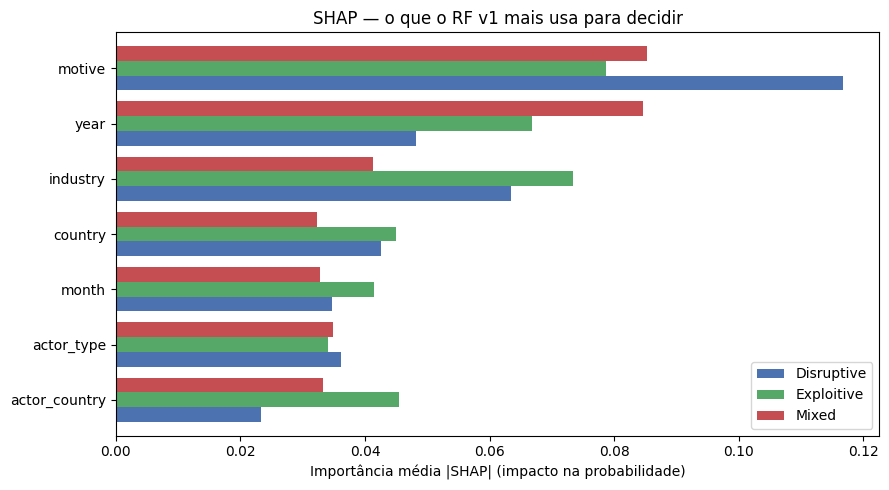

Ranking das features (soma das 3 classes):
motive           25.6 %
year             18.2 %
industry         16.3 %
country          10.9 %
month            10.0 %
actor_type        9.6 %
actor_country     9.3 %
dtype: object


In [ ]:
# ============================================================
# CÉLULA 5.1 — CALCULAR O SHAP E A IMPORTÂNCIA DE CADA FEATURE
# ============================================================
import shap

# Amostra de "fundo": eventos de treino usados como referência pelo SHAP
FUNDO = df_prep.loc[idx_treino].sample(50, random_state=SEMENTE)

def shap_por_feature(modelo, X_amostra, features):
    '''
    Calcula os valores SHAP diretamente nas features ORIGINAIS (actor_type, motive, ...).
    Usamos o explicador "exato" do SHAP, que testa combinações das features e
    funciona com o pipeline inteiro (pré-processamento + Random Forest).
    Retorna: (valores[amostra, feature, classe], valor_base[classe], classes)
    '''
    # O SHAP trabalha com números: trocamos cada categoria por um código (0, 1, 2...)
    # e, antes de chamar o modelo, desfazemos a troca.
    categorias = {f: pd.Index(df_prep[f].astype(str).unique())
                  for f in features if f not in pc.COLUNAS_NUMERICAS}

    def codificar(X):
        return np.column_stack([categorias[f].get_indexer(X[f].astype(str)) if f in categorias
                                else X[f].to_numpy() for f in features]).astype(float)

    def prever(A):
        X = pd.DataFrame({f: (categorias[f][A[:, j].astype(int)] if f in categorias
                              else A[:, j].astype(int)) for j, f in enumerate(features)})
        return modelo.predict_proba(X)

    explicador = shap.Explainer(prever, shap.maskers.Independent(codificar(FUNDO[features]), max_samples=50),
                                algorithm="exact", feature_names=features)
    resultado = explicador(codificar(X_amostra[features]))
    valores = np.asarray(resultado.values)                   # (amostras, features, classes)
    base = np.asarray(resultado.base_values).reshape(len(X_amostra), -1)[0]

    # Verificação: valor base + soma das contribuições = probabilidade prevista pelo modelo
    erro = np.abs(base + valores.sum(axis=1) - modelo.predict_proba(X_amostra[features])).max()
    print(f"Verificação do SHAP (base + contribuições = probabilidade): erro máximo {erro:.4f} ->",
          "OK" if erro < 0.01 else "ATENÇÃO")
    return valores, base, list(modelo.classes_)

def grafico_importancia(agregado, features, classes, titulo, caminho):
    '''Gráfico de barras: importância média de cada feature, por classe.'''
    imp = pd.DataFrame(np.abs(agregado).mean(axis=0), index=features, columns=classes)
    imp = imp.loc[imp.sum(axis=1).sort_values().index]   # ordena da menor para a maior
    ax = imp.plot.barh(figsize=(9, 5), width=0.8, color=["#4C72B0", "#55A868", "#C44E52"])
    ax.set_xlabel("Importância média |SHAP| (impacto na probabilidade)")
    ax.set_title(titulo)
    plt.tight_layout(); plt.savefig(caminho, dpi=130); plt.show()
    return imp

# Amostra do conjunto de teste (100 eventos são suficientes para a explicação)
amostra = df_prep.loc[idx_teste].sample(100, random_state=SEMENTE)
shap_v1, base_v1, classes = shap_por_feature(modelo_v1, amostra[FEATURES_V1], FEATURES_V1)

imp_v1 = grafico_importancia(shap_v1, FEATURES_V1, classes,
                             "SHAP — o que o RF v1 mais usa para decidir",
                             f"{REPO}/artefatos/shap_importancia_v1.png")
ranking_v1 = imp_v1.sum(axis=1).sort_values(ascending=False)
POS_ANO = list(ranking_v1.index).index("year") + 1      # posição do ano no ranking
print("Ranking das features (soma das 3 classes):")
print((ranking_v1 / ranking_v1.sum() * 100).round(1).astype(str) + " %")

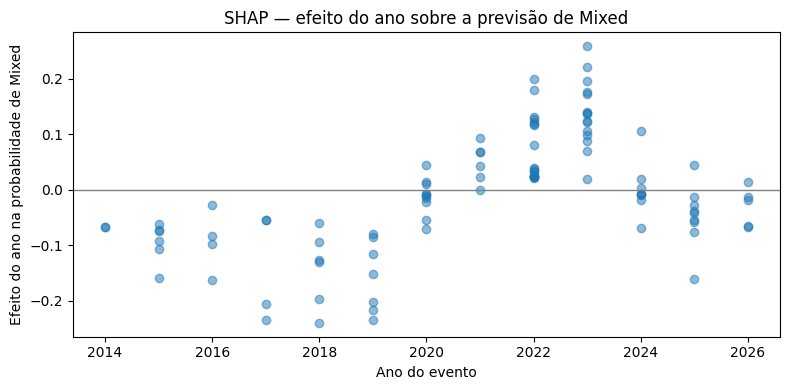

Efeito médio do ano na probabilidade de Mixed:
2014     -6.7 pontos percentuais
2015     -9.4 pontos percentuais
2016     -9.2 pontos percentuais
2017    -13.7 pontos percentuais
2018    -14.1 pontos percentuais
2019    -15.5 pontos percentuais
2020     -1.2 pontos percentuais
2021      4.9 pontos percentuais
2022      7.6 pontos percentuais
2023     13.8 pontos percentuais
2024      0.2 pontos percentuais
2025     -4.7 pontos percentuais
2026     -3.0 pontos percentuais
dtype: object


In [ ]:
# ============================================================
# CÉLULA 5.2 — O MODELO DEPENDE DO ANO? (efeito do year na classe Mixed)
# ============================================================
# Cada ponto é um evento: eixo X = ano do evento; eixo Y = quanto o ano
# aumentou (+) ou diminuiu (-) a probabilidade de o modelo prever Mixed.
pos_ano, pos_mixed = FEATURES_V1.index("year"), classes.index("Mixed")
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(amostra["year"], shap_v1[:, pos_ano, pos_mixed], alpha=0.5)
ax.axhline(0, color="gray", lw=1)
ax.set_xlabel("Ano do evento"); ax.set_ylabel("Efeito do ano na probabilidade de Mixed")
ax.set_title("SHAP — efeito do ano sobre a previsão de Mixed")
plt.tight_layout(); plt.savefig(f"{REPO}/artefatos/shap_ano_mixed.png", dpi=130); plt.show()

efeito = pd.Series(shap_v1[:, pos_ano, pos_mixed], index=amostra["year"].values)
print("Efeito médio do ano na probabilidade de Mixed:")
print((efeito.groupby(level=0).mean() * 100).round(1).astype(str) + " pontos percentuais")

Verificação do SHAP (base + contribuições = probabilidade): erro máximo 0.0000 -> OK


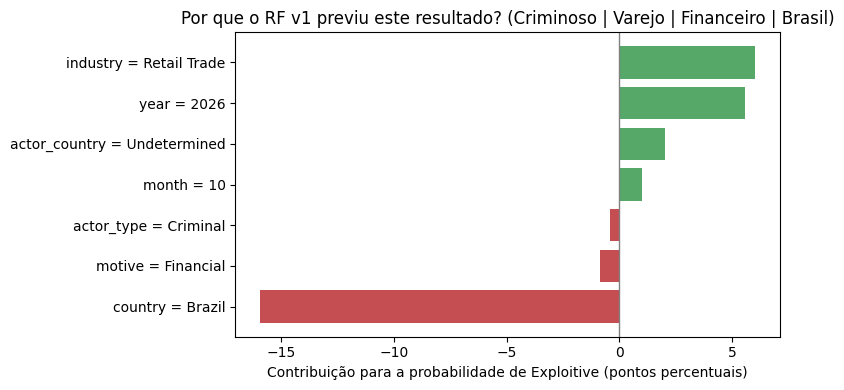

Probabilidades: {'Disruptive': '22%', 'Exploitive': '50%', 'Mixed': '28%'}
Ponto de partida (média do modelo) para Exploitive: 53%
  industry       +6.0 p.p.
  year           +5.6 p.p.
  actor_country  +2.0 p.p.
  month          +1.0 p.p.
  actor_type     -0.4 p.p.
  motive         -0.9 p.p.
  country        -15.9 p.p.
= previsão final para Exploitive: 50%


In [ ]:
# ============================================================
# CÉLULA 5.3 — EXPLICAÇÃO INDIVIDUAL: CENÁRIO DO MERCADO LIVRE
# ============================================================
cenario = pd.DataFrame([{
    "actor_type": "Criminal", "industry": "Retail Trade", "motive": "Financial",
    "country": "Brazil", "actor_country": "Undetermined", "actor": "Undetermined",
    "year": 2026, "month": 10,
}])

def explicar_cenario(modelo, features, titulo, caminho):
    probs = modelo.predict_proba(cenario[features])[0]
    valores, base, cls = shap_por_feature(modelo, cenario[features], features)
    k = int(np.argmax(probs))                        # classe prevista
    contrib = pd.Series(valores[0, :, k], index=features).sort_values()
    rotulos = [f"{f} = {cenario.iloc[0][f]}" for f in contrib.index]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(rotulos, contrib.values * 100, color=["#C44E52" if v < 0 else "#55A868" for v in contrib.values])
    ax.axvline(0, color="gray", lw=1)
    ax.set_xlabel(f"Contribuição para a probabilidade de {cls[k]} (pontos percentuais)")
    ax.set_title(titulo)
    plt.tight_layout(); plt.savefig(caminho, dpi=130); plt.show()
    print("Probabilidades:", {c: f"{p:.0%}" for c, p in zip(cls, probs)})
    print(f"Ponto de partida (média do modelo) para {cls[k]}: {base[k]:.0%}")
    for f, v in contrib.sort_values(ascending=False).items():
        print(f"  {f:<14} {v*100:+.1f} p.p.")
    print(f"= previsão final para {cls[k]}: {probs[k]:.0%}")

explicar_cenario(modelo_v1, FEATURES_V1,
                 "Por que o RF v1 previu este resultado? (Criminoso | Varejo | Financeiro | Brasil)",
                 f"{REPO}/artefatos/shap_cenario_v1.png")

# Guarda os gráficos do SHAP junto do experimento v1 no MLflow
with mlflow.start_run(run_id=RESULTADOS["RF v1 (Etapa 3)"]["run_id"]):
    for arq in ["shap_importancia_v1.png", "shap_ano_mixed.png", "shap_cenario_v1.png"]:
        mlflow.log_artifact(f"{REPO}/artefatos/{arq}", artifact_path="shap")

### Como interpretar o SHAP (confira com a sua saída)
- **Feature no topo do ranking (5.1):** é a pista que o modelo mais usa. No nosso teste prévio (importância por permutação), **`motive`** foi a mais importante.
- **Ano (`year`) com peso alto e efeito que muda com o tempo (5.2):** é um **risco**. O modelo pode estar aprendendo uma mudança na base ao longo dos anos, e não uma característica do ataque. Esse ponto entra no monitoramento e na matriz de riscos.
- **Feature no fim do ranking (ex.: `month`):** ajuda pouco e é candidata a ser removida.
- **`actor_type` com pouco peso:** o *tipo* de atacante é genérico demais. Hipótese: o **nome do grupo (`actor`)** traria mais informação, porque grupos conhecidos têm um padrão de ataque.
- **Cenário (5.3):** barras verdes aumentaram a probabilidade da classe prevista; vermelhas diminuíram.

## 6. Melhoria do modelo guiada pelo SHAP + ciclo de vida do modelo
O SHAP **não melhora o modelo sozinho**, mas mostra **onde mexer**. A partir dele, testamos duas hipóteses:

| Experimento | Mudança | Hipótese vinda do SHAP |
|---|---|---|
| **RF v2 (+ actor)** | Inclui o nome do grupo atacante; grupos com menos de 10 ataques viram "raros" | `actor_type` é genérico demais |
| **RF v3 (+ actor, sem month)** | Igual ao v2, mas sem o mês | `month` quase não ajuda |

**Regra de escolha:** vence o maior **F1 macro da validação cruzada** (o teste é só para confirmação, como na Etapa 3).

2026/11/19 21:42:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RF v2 (+ actor)                  F1 CV: 0.7025 ± 0.0088 | F1 teste: 0.7011 | Accuracy: 0.7260


2026/11/19 21:43:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RF v3 (+ actor, sem month)       F1 CV: 0.6868 ± 0.0117 | F1 teste: 0.7045 | Accuracy: 0.7281


,experimento,n_features,f1_cv,f1_teste,accuracy,f1_Mixed,versao_dados,config,commit,run_id
0,Baseline (Dummy),7,0.2306,0.2307,0.5291,0.0000,5a132adcd089,1.0,a3b2e64,52c6b0a719b54f21ac005dd3d283b982
1,RF v1 (Etapa 3),7,0.6445,0.6385,0.6725,0.5097,5a132adcd089,1.0,a3b2e64,296f45a6f94641faa26a3898ab7aeeb5
2,RF v2 (+ actor),8,0.7025,0.7011,0.7260,0.6408,5a132adcd089,1.0,a3b2e64,356b63333c374832b644423571be1560
3,"RF v3 (+ actor, sem month)",7,0.6868,0.7045,0.7281,0.6448,5a132adcd089,1.0,a3b2e64,f2b214bb0402484399b2b401cbc8f1a4



Campeão (maior F1 na validação cruzada): RF v2 (+ actor)
Ganho de F1 (teste) em relação ao v1: 0.0626


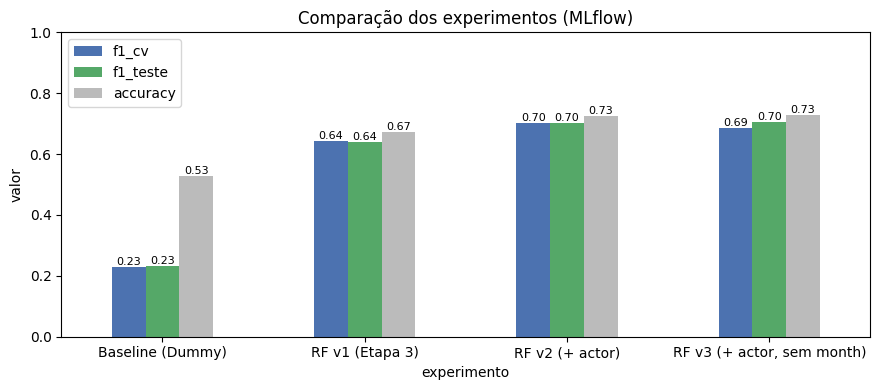

In [ ]:
# ============================================================
# CÉLULA 6.1 — NOVOS EXPERIMENTOS
# ============================================================
MIN_FREQ = 10
FEATURES_V2 = FEATURES_V1 + ["actor"]
FEATURES_V3 = [f for f in FEATURES_V2 if f != "month"]

rodar_experimento("RF v2 (+ actor)", "Inclui actor (grupos com < 10 ataques agrupados). Hipótese do SHAP.",
                  FEATURES_V2, min_frequencia=MIN_FREQ)
rodar_experimento("RF v3 (+ actor, sem month)", "Igual ao v2, sem month (pouco importante no SHAP).",
                  FEATURES_V3, min_frequencia=MIN_FREQ)

tabela = tabela_experimentos()
display(tabela)

# Escolha automática do campeão: maior F1 macro na validação cruzada (só Random Forest)
candidatos = {k: v for k, v in RESULTADOS.items() if k.startswith("RF")}
CAMPEAO = max(candidatos, key=lambda k: candidatos[k]["metricas"]["f1_macro_cv"])
print(f"\nCampeão (maior F1 na validação cruzada): {CAMPEAO}")
print("Ganho de F1 (teste) em relação ao v1:",
      round(RESULTADOS[CAMPEAO]["metricas"]["f1_macro"] - RESULTADOS["RF v1 (Etapa 3)"]["metricas"]["f1_macro"], 4))

# Gráfico de comparação para a apresentação
comp = tabela.set_index("experimento")[["f1_cv", "f1_teste", "accuracy"]]
ax = comp.plot.bar(figsize=(9, 4), rot=0, color=["#4C72B0", "#55A868", "#BBBBBB"])
ax.set_ylim(0, 1); ax.set_title("Comparação dos experimentos (MLflow)"); ax.set_ylabel("valor")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(f"{REPO}/artefatos/comparacao_experimentos.png", dpi=130); plt.show()

ExactExplainer explainer: 101it [00:22,  2.53it/s]


Verificação do SHAP (base + contribuições = probabilidade): erro máximo 0.0000 -> OK


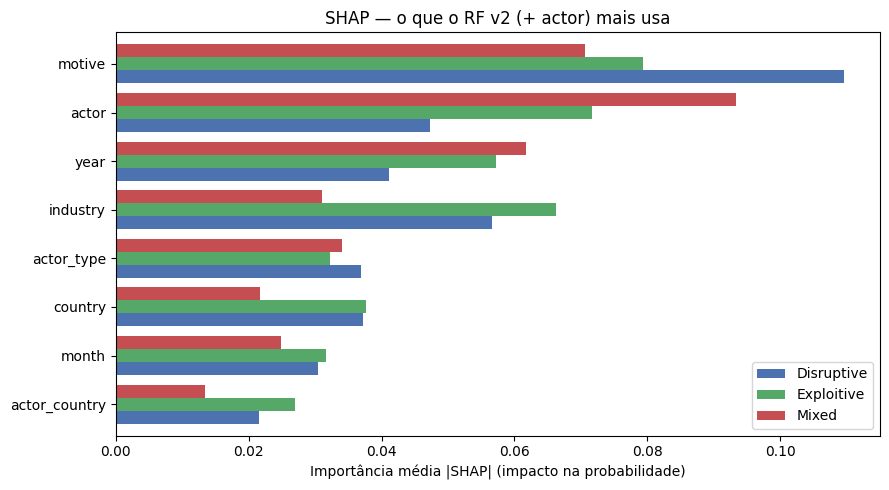

motive           22.9 %
actor            18.7 %
year             14.1 %
industry         13.6 %
actor_type        9.1 %
country           8.5 %
month             7.7 %
actor_country     5.5 %
dtype: object
Verificação do SHAP (base + contribuições = probabilidade): erro máximo 0.0000 -> OK


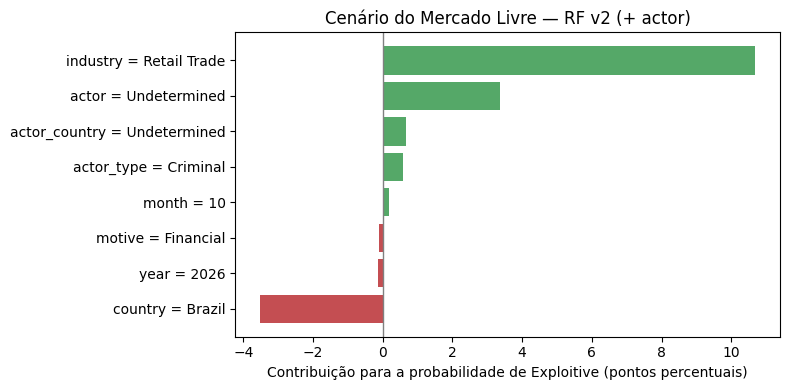

Probabilidades: {'Disruptive': '20%', 'Exploitive': '66%', 'Mixed': '14%'}
Ponto de partida (média do modelo) para Exploitive: 54%
  industry       +10.7 p.p.
  actor          +3.4 p.p.
  actor_country  +0.7 p.p.
  actor_type     +0.6 p.p.
  month          +0.2 p.p.
  motive         -0.1 p.p.
  year           -0.1 p.p.
  country        -3.5 p.p.
= previsão final para Exploitive: 66%


In [ ]:
# ============================================================
# CÉLULA 6.2 — SHAP DO CAMPEÃO (o actor passou a ajudar?)
# ============================================================
modelo_campeao = RESULTADOS[CAMPEAO]["modelo"]
FEATURES_CAMPEAO = RESULTADOS[CAMPEAO]["features"]

shap_c, base_c, _ = shap_por_feature(modelo_campeao, amostra[FEATURES_CAMPEAO], FEATURES_CAMPEAO)
imp_c = grafico_importancia(shap_c, FEATURES_CAMPEAO, classes,
                            f"SHAP — o que o {CAMPEAO} mais usa",
                            f"{REPO}/artefatos/shap_importancia_campeao.png")
ranking_c = imp_c.sum(axis=1).sort_values(ascending=False)
print((ranking_c / ranking_c.sum() * 100).round(1).astype(str) + " %")

explicar_cenario(modelo_campeao, FEATURES_CAMPEAO, f"Cenário do Mercado Livre — {CAMPEAO}",
                 f"{REPO}/artefatos/shap_cenario_campeao.png")

with mlflow.start_run(run_id=RESULTADOS[CAMPEAO]["run_id"]):
    for arq in ["shap_importancia_campeao.png", "shap_cenario_campeao.png"]:
        mlflow.log_artifact(f"{REPO}/artefatos/{arq}", artifact_path="shap")

### Model Registry: treinar um modelo ≠ gerenciar o ciclo de vida
Treinar é só o começo. No **Model Registry** do MLflow, cada modelo aprovado vira uma **versão numerada**, com descrição, status e um **apelido (`producao`)** que indica qual versão está em uso. Para trocar o modelo em produção, basta mover o apelido, e a versão antiga continua guardada (dá para voltar atrás).

In [ ]:
# ============================================================
# CÉLULA 6.3 — REGISTRAR VERSÕES E PROMOVER O CAMPEÃO
# ============================================================
NOME_MODELO = "cedb_tipo_evento"
client = MlflowClient()

def registrar_versao(chave, status, descricao):
    versao = mlflow.register_model(RESULTADOS[chave]["model_uri"], NOME_MODELO).version
    client.update_model_version(NOME_MODELO, versao, description=descricao)
    client.set_model_version_tag(NOME_MODELO, versao, "status", status)
    client.set_model_version_tag(NOME_MODELO, versao, "experimento", chave)
    client.set_model_version_tag(NOME_MODELO, versao, "versao_dados", VERSAO_DADOS)
    return versao

ver_v1 = registrar_versao("RF v1 (Etapa 3)", "substituido",
                          "Modelo da Etapa 3 (7 features). Substituído pelo campeão da Etapa 4.")
ver_campeao = registrar_versao(CAMPEAO, "em_producao",
                               f"Campeão da Etapa 4 ({CAMPEAO}), escolhido pelo F1 macro da validação cruzada.")

# Apelido "producao" aponta para a versão em uso
client.set_registered_model_alias(NOME_MODELO, "producao", ver_campeao)

versoes = client.search_model_versions(f"name='{NOME_MODELO}'")
display(pd.DataFrame([{
    "versao": v.version, "experimento": v.tags.get("experimento"), "status": v.tags.get("status"),
    "apelidos": ", ".join(getattr(v, "aliases", []) or []), "run_id": v.run_id,
} for v in sorted(versoes, key=lambda v: int(v.version))]))

# Prova: carregar o modelo pelo apelido, como um sistema em produção faria
try:
    modelo_producao = mlflow.sklearn.load_model(f"models:/{NOME_MODELO}@producao")
    print("\nModelo carregado do registro (apelido 'producao'). Previsão do cenário:",
          modelo_producao.predict(cenario[FEATURES_CAMPEAO])[0])
except Exception as erro:
    print("\nNão foi possível carregar o modelo pelo apelido nesta versão do MLflow:", erro)

Successfully registered model 'cedb_tipo_evento'.
Created version '1' of model 'cedb_tipo_evento'.
Registered model 'cedb_tipo_evento' already exists. Creating a new version of this model...
Created version '2' of model 'cedb_tipo_evento'.


,versao,experimento,status,apelidos,run_id
0,1,RF v1 (Etapa 3),substituido,,296f45a6f94641faa26a3898ab7aeeb5
1,2,RF v2 (+ actor),em_producao,,356b63333c374832b644423571be1560



Modelo carregado do registro (apelido 'producao'). Previsão do cenário: Exploitive


In [ ]:
# ============================================================
# CÉLULA 6.4 — NOVA VERSÃO DA CONFIGURAÇÃO + COMMIT NO GIT
# ============================================================
CONFIG["versao_config"] = "2.0"
CONFIG["modelo"] = {
    "versao": CAMPEAO,
    "features": FEATURES_CAMPEAO,
    "min_frequencia_categoria": RESULTADOS[CAMPEAO]["min_frequencia"],
    "registro_mlflow": f"{NOME_MODELO} v{ver_campeao} (apelido: producao)",
    "run_id": RESULTADOS[CAMPEAO]["run_id"],
}
salvar_config()

git("add", ".")
git("commit", "-q", "-m", f"v2.0: config com o campeão {CAMPEAO} + artefatos do SHAP")
git("log", "--oneline")
print("\nDiferença entre as versões da configuração (o que mudou):")
git("diff", "HEAD~1", "HEAD", "--", "config.json")

5cd561f v2.0: config com o campeão RF v2 (+ actor) + artefatos do SHAP
a3b2e64 v1.0: pipeline da Etapa 3, config v1.0 e Data Card

Diferença entre as versões da configuração (o que mudou):
diff --git a/config.json b/config.json
index dacadb1..634b0e4 100644
--- a/config.json
+++ b/config.json
@@ -1,5 +1,5 @@
 {
-  "versao_config": "1.0",
+  "versao_config": "2.0",
   "arquivo_dados": "cyber_events_tratado.csv",
   "alvo": "event_type",
   "classes_validas": [
@@ -28,7 +28,7 @@
     }
   },
   "modelo": {
-    "versao": "v1",
+    "versao": "RF v2 (+ actor)",
     "features": [
       "actor_type",
       "industry",
@@ -36,9 +36,12 @@
       "country",
       "actor_country",
       "year",
-      "month"
+      "month",
+      "actor"
     ],
-    "min_frequencia_categoria": null
+    "min_frequencia_categoria": 10,
+    "registro_mlflow": "cedb_tipo_evento v2 (apelido: producao)",
+    "run_id": "356b63333c374832b644423571be1560"
   },
   "parametros_rf": {
     "n_estimators": 100,


## 7. Monitoramento
**Pergunta do professor:** *depois que o modelo entra em produção, como sabemos que ele continua funcionando adequadamente?*

**Simulação:** fingimos que o modelo foi colocado em produção no fim de **2024**, treinado só com eventos de 2014 a 2024. Depois, **chegam os eventos de 2025 e 2026** (o "lote novo"). Verificamos:
- **Dados:** valores ausentes, qualidade (validação), mudança de distribuição (**data drift**, medido pelo **PSI**) e categorias nunca vistas;
- **Modelo:** desempenho, erros por classe e **model drift** (mudança na distribuição das classes e das previsões).

**Como ler o PSI:** abaixo de 0,10 = estável (OK) | 0,10 a 0,25 = mudança moderada (ATENÇÃO) | acima de 0,25 = mudança forte (ALERTA).

Na vida real, o tipo verdadeiro de um ataque só é conhecido **depois da investigação**, então o desempenho seria medido com atraso, conforme os rótulos chegam.

In [ ]:
# ============================================================
# CÉLULA 7.1 — SIMULAÇÃO: CHEGADA DE UM NOVO LOTE DE DADOS
# ============================================================
M = CONFIG["monitoramento"]
F = FEATURES_CAMPEAO
corte = M["ano_corte_simulacao"]

referencia = df_prep[df_prep["year"] <= corte]          # o que o modelo "conhecia"
novo_lote = df_prep[df_prep["year"] > corte]            # dados que chegaram depois
print(f"Referência (até {corte}): {len(referencia)} eventos | Lote novo ({corte+1}+): {len(novo_lote)} eventos\n")

# Modelo "em produção" da simulação: mesma configuração do campeão, treinado só até 2024
ref_tr, ref_te = train_test_split(referencia.index, test_size=CONFIG["proporcao_teste"],
                                  random_state=SEMENTE, stratify=referencia[ALVO])
modelo_sim = pc.criar_modelo(F, CONFIG["parametros_rf"], RESULTADOS[CAMPEAO]["min_frequencia"])
modelo_sim.fit(referencia.loc[ref_tr, F], referencia.loc[ref_tr, ALVO])

met_ref = pc.avaliar(modelo_sim, referencia.loc[ref_te, F], referencia.loc[ref_te, ALVO])
met_novo = pc.avaliar(modelo_sim, novo_lote[F], novo_lote[ALVO])

indicadores = []
def indicador(dimensao, nome, ref, novo, limite, status, acao):
    indicadores.append({"dimensao": dimensao, "indicador": nome, "referencia": ref,
                        "lote_novo": novo, "limite": limite, "status": status, "acao": acao})

# ---------------- DADOS ----------------
val_novo = pc.validar_dados(df[df["year"] > corte], colunas_necessarias, ALVO, CONFIG["classes_validas"])
falhas = int((val_novo["resultado"] == "FALHA").sum())
indicador("Dados", "Qualidade: falhas na validação", 0, falhas, "0 falhas",
          "OK" if falhas == 0 else "ALERTA", "Bloquear o uso do lote e corrigir a fonte")

nulos_novo = float(df.loc[df["year"] > corte, F].isna().mean().max())
indicador("Dados", "Valores ausentes (maior % entre as features)",
          f"{df.loc[df['year'] <= corte, F].isna().mean().max():.1%}", f"{nulos_novo:.1%}",
          f"< {M['limite_nulos']:.0%}", "OK" if nulos_novo < M["limite_nulos"] else "ALERTA",
          "Investigar a coleta; registrar imputação")

for f in [c for c in F if c not in ("year", "month")]:
    valor = pc.psi(referencia[f], novo_lote[f])
    indicador("Dados", f"Data drift (PSI) — {f}", "0", round(valor, 3),
              f"< {M['psi_atencao']} / < {M['psi_alerta']}",
              pc.status_psi(valor, M["psi_atencao"], M["psi_alerta"]),
              "Analisar a causa da mudança; avaliar retreino")

pct_novas = {f: float((~novo_lote[f].isin(set(referencia[f]))).mean()) for f in F if f not in ("year", "month")}
f_max = max(pct_novas, key=pct_novas.get)
indicador("Dados", f"Eventos com categoria nunca vista (pior: {f_max})", "0%", f"{pct_novas[f_max]:.1%}",
          f"< {M['limite_categorias_novas']:.0%}",
          "OK" if pct_novas[f_max] < M["limite_categorias_novas"] else "ALERTA",
          "Retreinar para aprender as categorias novas")

# ---------------- MODELO ----------------
queda = met_ref["f1_macro"] - met_novo["f1_macro"]
indicador("Modelo", "Desempenho: F1 macro", met_ref["f1_macro"], met_novo["f1_macro"],
          f"queda < {M['queda_f1_alerta']}", "OK" if queda < M["queda_f1_alerta"] else "ALERTA",
          "Retreinar com dados recentes e revalidar")
for c in classes:
    indicador("Modelo", f"Erros: F1 da classe {c}", met_ref[f"f1_{c}"], met_novo[f"f1_{c}"],
              f"queda < {M['queda_f1_alerta']}",
              "OK" if met_ref[f"f1_{c}"] - met_novo[f"f1_{c}"] < M["queda_f1_alerta"] else "ALERTA",
              "Revisar os erros dessa classe")

psi_alvo = pc.psi(referencia[ALVO], novo_lote[ALVO])
indicador("Modelo", "Model drift: distribuição real das classes (PSI)", "0", round(psi_alvo, 3),
          f"< {M['psi_alerta']}", pc.status_psi(psi_alvo, M["psi_atencao"], M["psi_alerta"]),
          "Verificar mudança de critério na CEDB")
psi_prev = pc.psi(modelo_sim.predict(referencia.loc[ref_te, F]), modelo_sim.predict(novo_lote[F]))
indicador("Modelo", "Model drift: distribuição das previsões (PSI)", "0", round(psi_prev, 3),
          f"< {M['psi_alerta']}", pc.status_psi(psi_prev, M["psi_atencao"], M["psi_alerta"]),
          "Comparar previsões com os rótulos que chegarem")

relatorio_monitoramento = pd.DataFrame(indicadores)
relatorio_monitoramento.to_csv(f"{REPO}/artefatos/relatorio_monitoramento_simulado.csv",
                               index=False, encoding="utf-8-sig")
display(relatorio_monitoramento)
print("\nResumo:", relatorio_monitoramento["status"].value_counts().to_dict())

Referência (até 2024): 14596 eventos | Lote novo (2025+): 2667 eventos



,dimensao,indicador,referencia,lote_novo,limite,status,acao
0,Dados,Qualidade: falhas na validação,0,0,0 falhas,OK,Bloquear o uso do lote e corrigir a fonte
1,Dados,Valores ausentes (maior % entre as features),0.0%,0.0%,< 5%,OK,Investigar a coleta; registrar imputação
2,Dados,Data drift (PSI) — actor_type,0,0.321,< 0.1 / < 0.25,ALERTA,Analisar a causa da mudança; avaliar retreino
3,Dados,Data drift (PSI) — industry,0,0.232,< 0.1 / < 0.25,ATENÇÃO,Analisar a causa da mudança; avaliar retreino
4,Dados,Data drift (PSI) — motive,0,0.093,< 0.1 / < 0.25,OK,Analisar a causa da mudança; avaliar retreino
5,Dados,Data drift (PSI) — country,0,0.117,< 0.1 / < 0.25,ATENÇÃO,Analisar a causa da mudança; avaliar retreino
6,Dados,Data drift (PSI) — actor_country,0,0.202,< 0.1 / < 0.25,ATENÇÃO,Analisar a causa da mudança; avaliar retreino
7,Dados,Data drift (PSI) — actor,0,0.46,< 0.1 / < 0.25,ALERTA,Analisar a causa da mudança; avaliar retreino
8,Dados,Eventos com categoria nunca vista (pior: actor),0%,21.0%,< 10%,ALERTA,Retreinar para aprender as categorias novas
9,Modelo,Desempenho: F1 macro,0.7315,0.5441,queda < 0.05,ALERTA,Retreinar com dados recentes e revalidar



Resumo: {'OK': 6, 'ALERTA': 6, 'ATENÇÃO': 3}


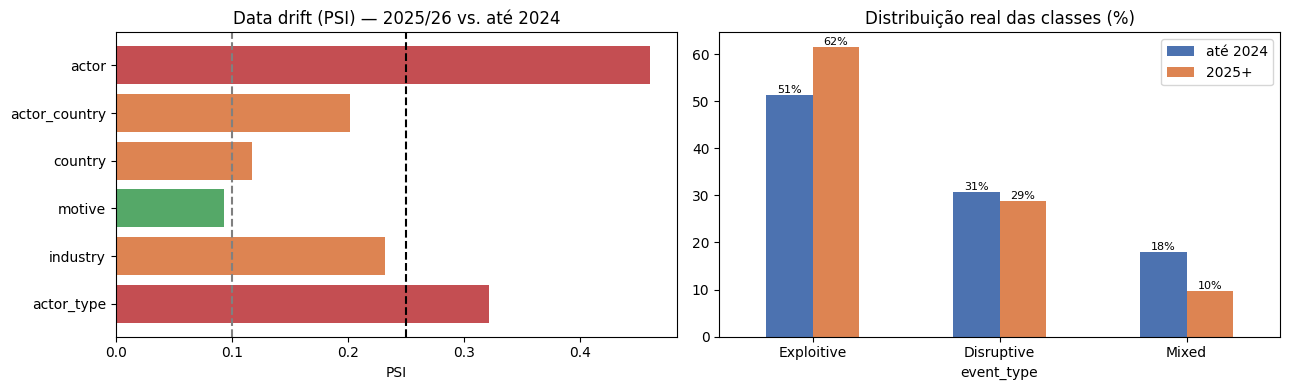

F1 macro no lote novo — sem retreino: 0.5482 | com retreino: 0.5792 (+0.0310)


2026/11/19 21:43:55 INFO mlflow.tracking.fluent: Experiment with name 'CEDB - Monitoramento simulado' does not exist. Creating a new experiment.


Viés regional (campeão) — F1 EUA: 0.6289 | demais países: 0.7576 | diferença: 0.1287


In [ ]:
# ============================================================
# CÉLULA 7.2 — GRÁFICOS DO MONITORAMENTO + AÇÃO (RETREINO SIMULADO)
# ============================================================
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

# (a) PSI de cada feature, com as linhas de limite
drift = relatorio_monitoramento[relatorio_monitoramento["indicador"].str.startswith("Data drift")]
nomes = drift["indicador"].str.replace("Data drift (PSI) — ", "", regex=False)
cores = drift["status"].map({"OK": "#55A868", "ATENÇÃO": "#DD8452", "ALERTA": "#C44E52"})
eixos[0].barh(nomes, drift["lote_novo"].astype(float), color=cores)
eixos[0].axvline(M["psi_atencao"], ls="--", color="gray"); eixos[0].axvline(M["psi_alerta"], ls="--", color="black")
eixos[0].set_title("Data drift (PSI) — 2025/26 vs. até 2024"); eixos[0].set_xlabel("PSI")

# (b) Distribuição das classes: referência x lote novo
dist = pd.DataFrame({"até 2024": referencia[ALVO].value_counts(normalize=True),
                     f"{corte+1}+": novo_lote[ALVO].value_counts(normalize=True)}) * 100
dist.plot.bar(ax=eixos[1], rot=0, color=["#4C72B0", "#DD8452"])
eixos[1].set_title("Distribuição real das classes (%)")
for c in eixos[1].containers:
    eixos[1].bar_label(c, fmt="%.0f%%", fontsize=8)
plt.tight_layout(); plt.savefig(f"{REPO}/artefatos/monitoramento_simulado.png", dpi=130); plt.show()

# ---------- AÇÃO: o retreino resolve? ----------
# Metade do lote novo entra no treino; a outra metade serve para avaliar.
nv_tr, nv_te = train_test_split(novo_lote.index, test_size=0.5, random_state=SEMENTE, stratify=novo_lote[ALVO])
modelo_retreinado = pc.criar_modelo(F, CONFIG["parametros_rf"], RESULTADOS[CAMPEAO]["min_frequencia"])
modelo_retreinado.fit(pd.concat([referencia[F], novo_lote.loc[nv_tr, F]]),
                      pd.concat([referencia[ALVO], novo_lote.loc[nv_tr, ALVO]]))
f1_sem = pc.avaliar(modelo_sim, novo_lote.loc[nv_te, F], novo_lote.loc[nv_te, ALVO])["f1_macro"]
f1_com = pc.avaliar(modelo_retreinado, novo_lote.loc[nv_te, F], novo_lote.loc[nv_te, ALVO])["f1_macro"]
print(f"F1 macro no lote novo — sem retreino: {f1_sem:.4f} | com retreino: {f1_com:.4f} ({f1_com - f1_sem:+.4f})")

# ---------- VIÉS: o modelo campeão funciona igual para EUA e demais países? ----------
teste = df_prep.loc[idx_teste]
eua = teste["country"] == "United States of America"
f1_eua = pc.avaliar(modelo_campeao, teste.loc[eua, F], teste.loc[eua, ALVO])["f1_macro"]
f1_outros = pc.avaliar(modelo_campeao, teste.loc[~eua, F], teste.loc[~eua, ALVO])["f1_macro"]
print(f"Viés regional (campeão) — F1 EUA: {f1_eua:.4f} | demais países: {f1_outros:.4f} | diferença: {abs(f1_eua - f1_outros):.4f}")

# ---------- Registrar o monitoramento no MLflow ----------
_ = mlflow.set_experiment("CEDB - Monitoramento simulado")
with mlflow.start_run(run_name=f"Lote {corte+1}-{int(df['year'].max())}"):
    mlflow.set_tags({"tipo": "monitoramento", "modelo_monitorado": CAMPEAO, "versao_dados": VERSAO_DADOS})
    mlflow.log_metrics({"f1_referencia": met_ref["f1_macro"], "f1_lote_novo": met_novo["f1_macro"],
                        "queda_f1": round(queda, 4), "psi_alvo": round(psi_alvo, 4),
                        "f1_sem_retreino": f1_sem, "f1_com_retreino": f1_com,
                        "f1_eua": f1_eua, "f1_outros_paises": f1_outros,
                        "n_alertas": int((relatorio_monitoramento["status"] == "ALERTA").sum())})
    mlflow.log_artifact(f"{REPO}/artefatos/relatorio_monitoramento_simulado.csv")
    mlflow.log_artifact(f"{REPO}/artefatos/monitoramento_simulado.png")
_ = mlflow.set_experiment(EXPERIMENTO)

In [ ]:
# ============================================================
# CÉLULA 7.3 — PLANO DE MONITORAMENTO (o que, como, limite e ação)
# ============================================================
plano = pd.DataFrame([
    # dimensão, indicador, como medir, frequência, limite, ação, responsável
    ["Dados", "Valores ausentes", "% de nulos por feature em cada lote", "A cada lote (mensal)", "> 5%", "Investigar a fonte; registrar imputação", "Engenharia de dados"],
    ["Dados", "Qualidade", "Validação automática (pipeline_cedb.validar_dados)", "A cada lote", "Qualquer FALHA", "Bloquear o lote até a correção", "Engenharia de dados"],
    ["Dados", "Mudança de distribuição / data drift", "PSI de cada feature vs. dados de treino", "Mensal", "PSI > 0,10 atenção; > 0,25 alerta", "Analisar a causa; avaliar retreino", "Cientista de dados"],
    ["Dados", "Categorias novas", "% de eventos com categoria nunca vista (ex.: novos grupos)", "Mensal", "> 10%", "Retreinar com dados recentes", "Cientista de dados"],
    ["Modelo", "Desempenho", "F1 macro nos eventos já investigados (rótulo real)", "Trimestral", "Queda > 0,05", "Retreinar e revalidar; nova versão no Registry", "Cientista de dados"],
    ["Modelo", "Erros", "Matriz de confusão; % de Mixed previsto como um tipo só", "Trimestral", "> 45%", "Revisar features e limiar de decisão", "Cientista de dados"],
    ["Modelo", "Model drift", "PSI das previsões e da distribuição real das classes", "Mensal", "PSI > 0,25", "Investigar mudança de critério da CEDB", "Cientista de dados"],
    ["Negócio", "Benefício esperado", "% de previsões que geraram ação de priorização", "Trimestral", "< 50%", "Rever a forma de uso com a equipe de segurança", "Gestor de segurança"],
    ["Negócio", "Impacto", "Tipo de incidente real na empresa vs. tipo priorizado", "Semestral", "Divergência recorrente", "Reavaliar o uso do modelo", "Gestor de segurança"],
    ["Negócio", "Utilização", "Nº de consultas ao modelo pela equipe", "Mensal", "Queda > 50%", "Entender o motivo (confiança, utilidade)", "Gestor de segurança"],
    ["Governança", "Incidentes", "Decisões erradas atribuídas ao modelo", "Contínuo", ">= 1 grave", "Revisão do modelo e registro do incidente", "Comitê de governança"],
    ["Governança", "Reclamações", "Feedback da equipe de segurança", "Contínuo", "Reclamação recorrente", "Revisão do modelo", "Comitê de governança"],
    ["Governança", "Vieses", "F1 macro por região (EUA vs. demais países)", "Trimestral", "Diferença > 0,10", "Ressalva no Model Card; rebalancear dados", "Comitê de governança"],
    ["Governança", "Necessidade de revisão", "Revisão do Model Card e da matriz de riscos", "Semestral", "Sempre", "Atualizar documentação e versão", "Comitê de governança"],
], columns=["dimensao", "indicador", "como_medir", "frequencia", "limite", "acao", "responsavel"])

plano.to_csv(f"{REPO}/docs/plano_monitoramento.csv", index=False, encoding="utf-8-sig")
display(plano)

,dimensao,indicador,como_medir,frequencia,limite,acao,responsavel
0,Dados,Valores ausentes,% de nulos por feature em cada lote,A cada lote (mensal),> 5%,Investigar a fonte; registrar imputação,Engenharia de dados
1,Dados,Qualidade,Validação automática (pipeline_cedb.validar_da...,A cada lote,Qualquer FALHA,Bloquear o lote até a correção,Engenharia de dados
2,Dados,Mudança de distribuição / data drift,PSI de cada feature vs. dados de treino,Mensal,"PSI > 0,10 atenção; > 0,25 alerta",Analisar a causa; avaliar retreino,Cientista de dados
3,Dados,Categorias novas,% de eventos com categoria nunca vista (ex.: n...,Mensal,> 10%,Retreinar com dados recentes,Cientista de dados
4,Modelo,Desempenho,F1 macro nos eventos já investigados (rótulo r...,Trimestral,"Queda > 0,05",Retreinar e revalidar; nova versão no Registry,Cientista de dados
5,Modelo,Erros,Matriz de confusão; % de Mixed previsto como u...,Trimestral,> 45%,Revisar features e limiar de decisão,Cientista de dados
6,Modelo,Model drift,PSI das previsões e da distribuição real das c...,Mensal,"PSI > 0,25",Investigar mudança de critério da CEDB,Cientista de dados
7,Negócio,Benefício esperado,% de previsões que geraram ação de priorização,Trimestral,< 50%,Rever a forma de uso com a equipe de segurança,Gestor de segurança
8,Negócio,Impacto,Tipo de incidente real na empresa vs. tipo pri...,Semestral,Divergência recorrente,Reavaliar o uso do modelo,Gestor de segurança
9,Negócio,Utilização,Nº de consultas ao modelo pela equipe,Mensal,Queda > 50%,"Entender o motivo (confiança, utilidade)",Gestor de segurança


## 8. Matriz de riscos
Riscos de **dados, modelo, privacidade, segurança e ética**, com probabilidade, impacto, mitigação e a **evidência encontrada no projeto**.

In [ ]:
# ============================================================
# CÉLULA 8.1 — MATRIZ DE RISCOS
# ============================================================
pct_eua = (df_prep["country"] == "United States of America").mean()
riscos = pd.DataFrame([
    ["Dados", "Viés geográfico: base concentrada nos EUA", "Alta", "Médio",
     f"{pct_eua:.0%} dos eventos são dos EUA; F1 EUA {f1_eua:.2f} vs. demais {f1_outros:.2f}",
     "Ressalva no Model Card; monitorar F1 por região"],
    ["Dados", "Eventos não divulgados não entram na base", "Alta", "Médio",
     "A CEDB é construída a partir de notícias públicas", "Usar como apoio, junto com dados internos da empresa"],
    ["Dados", "Mudança no critério de classificação ao longo do tempo", "Média", "Alto",
     f"Mixed caiu de {dist.iloc[:, 0].get('Mixed', 0):.0f}% para {dist.iloc[:, 1].get('Mixed', 0):.0f}% no lote novo",
     "Monitorar a distribuição das classes (PSI)"],
    ["Modelo", "Queda de desempenho com dados novos (drift)", "Alta", "Alto",
     f"F1 caiu de {met_ref['f1_macro']:.2f} para {met_novo['f1_macro']:.2f} na simulação",
     "Plano de monitoramento + retreino periódico"],
    ["Modelo", "Dependência do ano (year)", "Média", "Médio",
     f"No SHAP do v1, year ficou em {POS_ANO}º lugar entre {len(FEATURES_V1)} features",
     "Monitorar; avaliar substituir por features de contexto mais estáveis"],
    ["Modelo", "Baixo desempenho na classe Mixed (cenário mais grave)", "Alta", "Alto",
     f"F1 Mixed do campeão: {RESULTADOS[CAMPEAO]['metricas']['f1_Mixed']:.2f}",
     "Usar as probabilidades, não só a classe; revisão humana"],
    ["Modelo", "Vazamento de dados se colunas pós-evento forem incluídas", "Baixa", "Alto",
     "Etapa 3: event_subtype elevou o F1 para 0,94 (falso)", "Lista de features versionada no config.json"],
    ["Privacidade", "Exposição de nomes de organizações vítimas", "Baixa", "Médio",
     "organization e description existem na base, mas não são usadas no modelo", "Não usar nem exibir essas colunas (minimização, LGPD)"],
    ["Segurança", "Acesso indevido ao modelo e aos artefatos", "Média", "Médio",
     "O modelo revela como a empresa prioriza suas defesas", "Acesso restrito ao repositório e ao MLflow"],
    ["Segurança", "Dados de entrada manipulados", "Baixa", "Alto",
     "Um lote corrompido mudaria o modelo no retreino", "Validação automática bloqueia lotes com FALHA"],
    ["Ética", "Estigmatização de países ou grupos", "Média", "Médio",
     "actor_country e actor estão entre as features", "Usar só para priorizar defesas, nunca para atribuir culpa"],
    ["Ética", "Decisão automática sem revisão humana", "Média", "Alto",
     "Acurácia em torno de 70%: 3 em cada 10 previsões erradas", "O modelo apoia a decisão; a equipe de segurança decide"],
], columns=["categoria", "risco", "probabilidade", "impacto", "evidencia_no_projeto", "mitigacao"])

# Nível do risco = probabilidade x impacto
pontos = {"Baixa": 1, "Média": 2, "Alta": 3, "Baixo": 1, "Médio": 2, "Alto": 3}
riscos["nivel"] = (riscos["probabilidade"].map(pontos) * riscos["impacto"].map(pontos)).map(
    lambda p: "ALTO" if p >= 6 else ("MÉDIO" if p >= 3 else "BAIXO"))
riscos = riscos.sort_values("nivel", key=lambda s: s.map({"ALTO": 0, "MÉDIO": 1, "BAIXO": 2}))
riscos.to_csv(f"{REPO}/docs/matriz_riscos.csv", index=False, encoding="utf-8-sig")
display(riscos)
print(riscos["nivel"].value_counts().to_dict())

,categoria,risco,probabilidade,impacto,evidencia_no_projeto,mitigacao,nivel
0,Dados,Viés geográfico: base concentrada nos EUA,Alta,Médio,47% dos eventos são dos EUA; F1 EUA 0.63 vs. d...,Ressalva no Model Card; monitorar F1 por região,ALTO
1,Dados,Eventos não divulgados não entram na base,Alta,Médio,A CEDB é construída a partir de notícias públicas,"Usar como apoio, junto com dados internos da e...",ALTO
2,Dados,Mudança no critério de classificação ao longo ...,Média,Alto,Mixed caiu de 18% para 10% no lote novo,Monitorar a distribuição das classes (PSI),ALTO
3,Modelo,Queda de desempenho com dados novos (drift),Alta,Alto,F1 caiu de 0.73 para 0.54 na simulação,Plano de monitoramento + retreino periódico,ALTO
5,Modelo,Baixo desempenho na classe Mixed (cenário mais...,Alta,Alto,F1 Mixed do campeão: 0.64,"Usar as probabilidades, não só a classe; revis...",ALTO
11,Ética,Decisão automática sem revisão humana,Média,Alto,Acurácia em torno de 70%: 3 em cada 10 previsõ...,O modelo apoia a decisão; a equipe de seguranç...,ALTO
6,Modelo,Vazamento de dados se colunas pós-evento forem...,Baixa,Alto,"Etapa 3: event_subtype elevou o F1 para 0,94 (...",Lista de features versionada no config.json,MÉDIO
4,Modelo,Dependência do ano (year),Média,Médio,"No SHAP do v1, year ficou em 2º lugar entre 7 ...",Monitorar; avaliar substituir por features de ...,MÉDIO
9,Segurança,Dados de entrada manipulados,Baixa,Alto,Um lote corrompido mudaria o modelo no retreino,Validação automática bloqueia lotes com FALHA,MÉDIO
8,Segurança,Acesso indevido ao modelo e aos artefatos,Média,Médio,O modelo revela como a empresa prioriza suas d...,Acesso restrito ao repositório e ao MLflow,MÉDIO


{'ALTO': 6, 'MÉDIO': 5, 'BAIXO': 1}


## 9. Model Card
O **Model Card** é a "bula" do modelo: explica para que ele serve, com quais dados foi treinado, quão bem funciona, onde **não** deve ser usado, quais são os riscos e quem é o responsável. Ele é gerado automaticamente a partir dos resultados registrados.

In [ ]:
# ============================================================
# CÉLULA 9.1 — GERAR O MODEL CARD
# ============================================================
mc = RESULTADOS[CAMPEAO]["metricas"]
mb = RESULTADOS["Baseline (Dummy)"]["metricas"]
top3 = ", ".join(ranking_c.index[:3])

model_card = f'''# Model Card — {NOME_MODELO} (versão {ver_campeao}, apelido `producao`)

| Campo | Valor |
|---|---|
| Modelo | Random Forest ({CONFIG["parametros_rf"]["n_estimators"]} árvores, class_weight=balanced) — {CAMPEAO} |
| Data | {datetime.now(timezone.utc).strftime("%Y-%m-%d")} |
| Versão dos dados | `{VERSAO_DADOS}` (SHA-256) |
| Configuração / commit | config v{CONFIG["versao_config"]} / `{commit_atual()}` |
| Run no MLflow | `{RESULTADOS[CAMPEAO]["run_id"]}` |

## Objetivo
Classificar o **tipo de efeito** de um ataque cibernético (Disruptive, Exploitive ou Mixed) a partir do contexto do evento, para **apoiar a priorização de riscos e recursos de segurança** (ex.: disponibilidade vs. proteção de dados).

## Dados utilizados
Cyber Events Database (CEDB, University of Maryland), eventos de {int(df["year"].min())} a {int(df["year"].max())}, {len(df_prep)} eventos após a preparação (classe Undetermined removida). Features: {", ".join(FEATURES_CAMPEAO)}. Detalhes no `data_card.md`.

## População / contexto
Ataques cibernéticos **divulgados publicamente** contra organizações de vários países e setores, com forte concentração nos EUA ({pct_eua:.0%}). Contexto de uso: equipe de segurança de uma empresa de comércio eletrônico (cenário Mercado Livre).

## Métricas (conjunto de teste: {len(idx_teste)} eventos)
| Métrica | Baseline | Modelo |
|---|---|---|
| F1 macro (principal) | {mb["f1_macro"]:.4f} | **{mc["f1_macro"]:.4f}** |
| F1 macro — validação cruzada | {mb["f1_macro_cv"]:.4f} | {mc["f1_macro_cv"]:.4f} ± {mc["f1_macro_cv_desvio"]:.4f} |
| Recall macro | {mb["recall_macro"]:.4f} | {mc["recall_macro"]:.4f} |
| Accuracy | {mb["accuracy"]:.4f} | {mc["accuracy"]:.4f} |
| F1 Disruptive / Exploitive / Mixed | — | {mc["f1_Disruptive"]:.2f} / {mc["f1_Exploitive"]:.2f} / {mc["f1_Mixed"]:.2f} |

**Explicabilidade (SHAP):** as features mais importantes são {top3}.

## Limitações
- Desempenho mais fraco na classe **Mixed** (F1 {mc["f1_Mixed"]:.2f}), justamente o cenário mais grave.
- **Queda com dados novos:** na simulação de monitoramento, o F1 caiu de {met_ref["f1_macro"]:.2f} para {met_novo["f1_macro"]:.2f}; o retreino recuperou parte ({f1_sem:.2f} → {f1_com:.2f}).
- Usa o **ano** do evento ({POS_ANO}º lugar no SHAP do v1), o que pode refletir mudanças da base, e não do ataque; anos novos ficam fora do que o modelo conhece.
- Não prevê eventos sem informação (Undetermined): sempre escolhe uma das 3 classes.
- Desempenho diferente por região: F1 EUA {f1_eua:.2f} vs. demais países {f1_outros:.2f}.

## Usos recomendados
- Apoiar a **priorização de defesas** (disponibilidade x proteção de dados) a partir de perfis de ameaça.
- Usar as **probabilidades** das três classes, e não só a classe prevista.
- Análises de tendência, sempre com revisão da equipe de segurança.

## Usos não recomendados
- Decisão automática sem revisão humana.
- Atribuir culpa ou responsabilidade a países ou grupos.
- Resposta a um incidente em andamento (o modelo não analisa evidências técnicas do ataque).
- Uso fora do contexto de organizações (ex.: ataques a pessoas físicas).

## Riscos
Ver `matriz_riscos.csv`: {int((riscos["nivel"] == "ALTO").sum())} riscos de nível ALTO, entre eles drift dos dados, baixo desempenho em Mixed e decisão sem revisão humana.

## Aspectos éticos
Base pública, sem dados pessoais nas features; nomes de vítimas (organization) e descrições não são usados (minimização de dados, alinhada à LGPD). As features geopolíticas (actor_country, actor) exigem cuidado para não reforçar estereótipos; o modelo serve para **proteger**, não para acusar.

## Monitoramento
Plano em `plano_monitoramento.csv` (dados, modelo, negócio e governança), com revisão deste Model Card a cada semestre.

## Responsável pelo modelo
Gabriela Vitoria Vieira, Keila Kaori Horiye e Luanna Garla — Universidade Estadual de Londrina (UEL), disciplina de Mineração de Dados.
'''
with open(f"{REPO}/docs/model_card.md", "w", encoding="utf-8") as f:
    f.write(model_card)
with mlflow.start_run(run_id=RESULTADOS[CAMPEAO]["run_id"]):
    mlflow.log_artifact(f"{REPO}/docs/model_card.md")
display(Markdown(model_card))

# Model Card — cedb_tipo_evento (versão 2, apelido `producao`)

| Campo | Valor |
|---|---|
| Modelo | Random Forest (100 árvores, class_weight=balanced) — RF v2 (+ actor) |
| Data | 2026-11-19 |
| Versão dos dados | `5a132adcd089` (SHA-256) |
| Configuração / commit | config v2.0 / `5cd561f` |
| Run no MLflow | `356b63333c374832b644423571be1560` |

## Objetivo
Classificar o **tipo de efeito** de um ataque cibernético (Disruptive, Exploitive ou Mixed) a partir do contexto do evento, para **apoiar a priorização de riscos e recursos de segurança** (ex.: disponibilidade vs. proteção de dados).

## Dados utilizados
Cyber Events Database (CEDB, University of Maryland), eventos de 2014 a 2026, 17263 eventos após a preparação (classe Undetermined removida). Features: actor_type, industry, motive, country, actor_country, year, month, actor. Detalhes no `data_card.md`.

## População / contexto
Ataques cibernéticos **divulgados publicamente** contra organizações de vários países e setores, com forte concentração nos EUA (47%). Contexto de uso: equipe de segurança de uma empresa de comércio eletrônico (cenário Mercado Livre).

## Métricas (conjunto de teste: 3453 eventos)
| Métrica | Baseline | Modelo |
|---|---|---|
| F1 macro (principal) | 0.2307 | **0.7011** |
| F1 macro — validação cruzada | 0.2306 | 0.7025 ± 0.0088 |
| Recall macro | 0.3333 | 0.7007 |
| Accuracy | 0.5291 | 0.7260 |
| F1 Disruptive / Exploitive / Mixed | — | 0.69 / 0.77 / 0.64 |

**Explicabilidade (SHAP):** as features mais importantes são motive, actor, year.

## Limitações
- Desempenho mais fraco na classe **Mixed** (F1 0.64), justamente o cenário mais grave.
- **Queda com dados novos:** na simulação de monitoramento, o F1 caiu de 0.73 para 0.54; o retreino recuperou parte (0.55 → 0.58).
- Usa o **ano** do evento (2º lugar no SHAP do v1), o que pode refletir mudanças da base, e não do ataque; anos novos ficam fora do que o modelo conhece.
- Não prevê eventos sem informação (Undetermined): sempre escolhe uma das 3 classes.
- Desempenho diferente por região: F1 EUA 0.63 vs. demais países 0.76.

## Usos recomendados
- Apoiar a **priorização de defesas** (disponibilidade x proteção de dados) a partir de perfis de ameaça.
- Usar as **probabilidades** das três classes, e não só a classe prevista.
- Análises de tendência, sempre com revisão da equipe de segurança.

## Usos não recomendados
- Decisão automática sem revisão humana.
- Atribuir culpa ou responsabilidade a países ou grupos.
- Resposta a um incidente em andamento (o modelo não analisa evidências técnicas do ataque).
- Uso fora do contexto de organizações (ex.: ataques a pessoas físicas).

## Riscos
Ver `matriz_riscos.csv`: 6 riscos de nível ALTO, entre eles drift dos dados, baixo desempenho em Mixed e decisão sem revisão humana.

## Aspectos éticos
Base pública, sem dados pessoais nas features; nomes de vítimas (organization) e descrições não são usados (minimização de dados, alinhada à LGPD). As features geopolíticas (actor_country, actor) exigem cuidado para não reforçar estereótipos; o modelo serve para **proteger**, não para acusar.

## Monitoramento
Plano em `plano_monitoramento.csv` (dados, modelo, negócio e governança), com revisão deste Model Card a cada semestre.

## Responsável pelo modelo
Gabriela Vitoria Vieira, Keila Kaori Horiye e Luanna Garla — Universidade Estadual de Londrina (UEL), disciplina de Mineração de Dados.


## 10. Pacote de Governança: README, requirements e entrega
Fechamos o repositório com:
- **README.md**: o que é o projeto, como reproduzir e onde está cada item da entrega;
- **requirements.txt**: versões exatas das bibliotecas (na Etapa 3 vimos que a versão muda o resultado!);
- **commit final** no Git e um **.zip** com tudo (repositório + registros do MLflow).

In [ ]:
# ============================================================
# CÉLULA 10.1 — README, REQUIREMENTS, COMMIT FINAL E DOWNLOAD
# ============================================================
import shap as _shap
requirements = f'''# Python {platform.python_version()}
pandas=={pd.__version__}
numpy=={np.__version__}
scikit-learn=={sklearn.__version__}
mlflow=={mlflow.__version__}
shap=={_shap.__version__}
matplotlib=={plt.matplotlib.__version__}
'''
with open(f"{REPO}/requirements.txt", "w") as f:
    f.write(requirements)

tabela_experimentos().to_csv(f"{REPO}/artefatos/registro_experimentos_mlflow.csv", index=False, encoding="utf-8-sig")

readme = f'''# Solução de IA governável — CEDB (tipo de efeito de ataques cibernéticos)
Projeto da disciplina de Mineração de Dados (UEL). Classifica o tipo de efeito de um ataque
(Disruptive, Exploitive, Mixed) para apoiar a priorização de riscos de segurança.

## Como reproduzir
1. Instale as dependências: `pip install -r requirements.txt`
2. Coloque `cyber_events_tratado.csv` (SHA-256 `{HASH_DADOS[:12]}...`) na pasta de execução.
3. Execute o notebook `Etapa_4_Governanca_CEDB.ipynb` do início ao fim (usa `pipeline_cedb.py` e `config.json`).
4. Os experimentos ficam em `mlflow.db` e `mlruns/` (para ver a interface: `mlflow ui --backend-store-uri sqlite:///mlflow.db`).

## Estrutura
| Arquivo | Conteúdo |
|---|---|
| `pipeline_cedb.py` | Código do pipeline (validação, preparação, modelo, avaliação, monitoramento) |
| `config.json` | Configuração versionada (v{CONFIG["versao_config"]}): features, parâmetros, limites |
| `docs/data_card.md`, `docs/dicionario_dados.csv`, `docs/registro_preparacao.csv` | Dataset documentado |
| `artefatos/registro_experimentos_mlflow.csv` + MLflow | Registro dos experimentos |
| `docs/model_card.md` | Model Card |
| `docs/plano_monitoramento.csv`, `artefatos/relatorio_monitoramento_simulado.csv` | Plano de monitoramento e simulação |
| `docs/matriz_riscos.csv` | Matriz de riscos |
| `artefatos/*.png` | Gráficos (matrizes de confusão, SHAP, monitoramento) |

## Modelo em produção
`{NOME_MODELO}` versão {ver_campeao} no MLflow Model Registry (apelido `producao`) — {CAMPEAO}.
'''
with open(f"{REPO}/README.md", "w", encoding="utf-8") as f:
    f.write(readme)

# Commit final + etiqueta de versão
git("add", ".")
git("commit", "-q", "-m", "v2.1: Model Card, plano de monitoramento, matriz de riscos, README e requirements")
git("tag", "-f", "entrega-etapa4")
print("Histórico de versões do repositório:")
git("log", "--oneline", "--decorate")

# Pacote final: repositório + MLflow (banco e artefatos)
pacote = "pacote_governanca_cedb"
if os.path.exists(pacote):
    shutil.rmtree(pacote)
shutil.copytree(REPO, f"{pacote}/{REPO}")
for item in ["mlflow.db", "mlruns"]:
    if os.path.isdir(item):
        shutil.copytree(item, f"{pacote}/{item}")
    elif os.path.exists(item):
        shutil.copy(item, pacote)
shutil.make_archive(pacote, "zip", pacote)
print(f"\nPacote criado: {pacote}.zip")
try:
    from google.colab import files
    files.download(f"{pacote}.zip")
except ImportError:
    pass

Histórico de versões do repositório:
bd87e5e (HEAD -> main, tag: entrega-etapa4) v2.1: Model Card, plano de monitoramento, matriz de riscos, README e requirements
5cd561f v2.0: config com o campeão RF v2 (+ actor) + artefatos do SHAP
a3b2e64 v1.0: pipeline da Etapa 3, config v1.0 e Data Card

Pacote criado: pacote_governanca_cedb.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# CÉLULA 10.2 — RESUMO PARA A APRESENTAÇÃO
# ============================================================
v1 = RESULTADOS["RF v1 (Etapa 3)"]["metricas"]
print("=" * 64)
print("RESUMO DA ETAPA 4")
print("=" * 64)
print(f"Dados: {len(df_prep)} eventos | versão {VERSAO_DADOS}")
print(f"Baseline F1: {mb['f1_macro']:.2f} | RF v1 (Etapa 3) F1: {v1['f1_macro']:.2f} | "
      f"Campeão ({CAMPEAO}) F1: {mc['f1_macro']:.2f}, accuracy: {mc['accuracy']:.2f}")
print(f"SHAP — features mais importantes do campeão: {top3}")
print(f"Model Registry: {NOME_MODELO} v{ver_campeao} = 'producao' (v{ver_v1} substituída)")
print(f"Monitoramento simulado: F1 {met_ref['f1_macro']:.2f} -> {met_novo['f1_macro']:.2f} no lote novo; "
      f"{int((relatorio_monitoramento['status'] == 'ALERTA').sum())} alertas; retreino: {f1_sem:.2f} -> {f1_com:.2f}")
print(f"Riscos: {riscos['nivel'].value_counts().to_dict()}")
print(f"Git: {len(git('log', '--oneline', mostrar=False).splitlines())} commits | config v{CONFIG['versao_config']}")

RESUMO DA ETAPA 4
Dados: 17263 eventos | versão 5a132adcd089
Baseline F1: 0.23 | RF v1 (Etapa 3) F1: 0.64 | Campeão (RF v2 (+ actor)) F1: 0.70, accuracy: 0.73
SHAP — features mais importantes do campeão: motive, actor, year
Model Registry: cedb_tipo_evento v2 = 'producao' (v1 substituída)
Monitoramento simulado: F1 0.73 -> 0.54 no lote novo; 6 alertas; retreino: 0.55 -> 0.58
Riscos: {'ALTO': 6, 'MÉDIO': 5, 'BAIXO': 1}
Git: 3 commits | config v2.0
